<a href="https://colab.research.google.com/github/neji03/data-analysis-project/blob/main/Projet_Analyse_de_Donn%C3%A9es.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Étape 0 : Préparation

## 0.1 Importation des bibliothèques nécessaires.

Dans cette étape, nous importons les bibliothèques Python nécessaires à la manipulation, à l'analyse statistique et à la visualisation des données.

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#Added by noor from :
import numpy as np
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
#To here
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster



## 0.2 Exploration générale des données

L'objectif de cette étape est de découvrir la structure de notre dataset, d'identifier les individus et les variables, et de vérifier la qualité des données avant de commencer les analyses statistiques.

### A. Chargement des données

In [2]:
df = pd.read_csv("table_projet_192x12_v2.csv",header=0,index_col=0)
df.head()

,experience_level,salary_class,company_size,wlb_class,experience_years,salary_usd,bonus_usd,layoff_risk,employee_satisfaction,weekly_hours,work_life_balance_score,career_growth_score
id,,,,,,,,,,,,
56273,Entry,Bas,Startup,Faible,1,71294,10925,0.420,59,49.6,45,65
5318,Entry,Bas,Medium,Bon,0,58060,7071,0.410,75,36.8,88,53
24801,Entry,Bas,Small,Bon,0,71859,7087,0.324,68,40.3,92,58
23124,Entry,Bas,Enterprise,Moyen,0,72703,7715,0.444,72,42.7,76,52
68909,Entry,Bas,Large,Faible,1,55219,9892,0.357,64,49.0,63,52


### B. Dimensions et structure

In [3]:
print("Dimensions (lignes, colonnes) :", df.shape)

print("Nombre d'individus :", df.shape[0])
print("Nombre de variables :", df.shape[1])
print("\n")
print("Noms des variables :")
print(df.columns.tolist())
print("\n")
print("Structure de dataset :")
df.info()

Dimensions (lignes, colonnes) : (192, 12)
Nombre d'individus : 192
Nombre de variables : 12


Noms des variables :
['experience_level', 'salary_class', 'company_size', 'wlb_class', 'experience_years', 'salary_usd', 'bonus_usd', 'layoff_risk', 'employee_satisfaction', 'weekly_hours', 'work_life_balance_score', 'career_growth_score']


Structure de dataset :
<class 'pandas.core.frame.DataFrame'>
Index: 192 entries, 56273 to 77594
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   experience_level         192 non-null    object 
 1   salary_class             192 non-null    object 
 2   company_size             192 non-null    object 
 3   wlb_class                192 non-null    object 
 4   experience_years         192 non-null    int64  
 5   salary_usd               192 non-null    int64  
 6   bonus_usd                192 non-null    int64  
 7   layoff_risk              192 non-null    flo

### C. Vérification des valeurs manquantes

In [4]:
print("Valeurs manquantes par variable :")
print(df.isnull().sum())
print("\n")
print("Nombre total de valeurs manquantes :",
      df.isnull().sum().sum())

Valeurs manquantes par variable :
experience_level           0
salary_class               0
company_size               0
wlb_class                  0
experience_years           0
salary_usd                 0
bonus_usd                  0
layoff_risk                0
employee_satisfaction      0
weekly_hours               0
work_life_balance_score    0
career_growth_score        0
dtype: int64


Nombre total de valeurs manquantes : 0


### D.Interprétation


*   La table contient 192 individus et 12 variables.


*   Les données sont composées de 8 variables quantitatives et 4 variables qualitatives (Dtype=object).

*   Aucune valeur manquante n'est présente.

# Étape 1 : Statistiques descriptives

## 1.1 Sélection des variables quantitatives

Dans cette étape, nous sélectionnons les huit variables quantitatives de notre dataset.

Ces variables représentent les caractéristiques numériques des offres d'emploi et constituent la base de notre analyse univariée.

In [26]:
QUANT = [
    "experience_years",
    "salary_usd",
    "bonus_usd",
    "layoff_risk",
    "employee_satisfaction",
    "weekly_hours",
    "work_life_balance_score",
    "career_growth_score"
]

QUALI = [
    "experience_level",
    "salary_class",
    "company_size",
    "wlb_class"
]

In [27]:
# Sélection des variables quantitatives
X = df[QUANT]

print("Variables quantitatives :")
print(X.columns.tolist())

print("\nDimensions de la table quantitative :", X.shape)

Variables quantitatives :
['experience_years', 'salary_usd', 'bonus_usd', 'layoff_risk', 'employee_satisfaction', 'weekly_hours', 'work_life_balance_score', 'career_growth_score']

Dimensions de la table quantitative : (192, 8)


## 1.2 Statistiques descriptives des variables quantitatives

Nous réalisons une analyse statistique descriptive afin de résumer les principales caractéristiques de chaque variable quantitative.

Les indicateurs étudiés sont :
- La moyenne et la médiane.
- L'écart-type.
- Les valeurs minimale et maximale.
- Les premier et troisième quartiles.
- La variance: pour mesurer la dispersion des valeurs autour de leur moyenne.
- L'asymétrie (skewness) : pour savoir si une distribution est symétrique ou si elle présente une déformation vers la gauche ou vers la droite.

In [28]:
# Calcul des statistiques descriptives
stats = X.describe().T

# Ajout de la médiane
stats["median"] = X.median()

# Ajout de la variance
stats["variance"] = X.var()

# Ajout de l'asymétrie
stats["skewness"] = X.skew()

# Affichage
display(stats.round(2))

,count,mean,std,min,25%,50%,75%,max,median,variance,skewness
experience_years,192.0,7.08,5.99,0.0,1.75,5.50,11.25,19.00,5.50,3.584000e+01,0.48
salary_usd,192.0,100167.17,38822.41,37586.0,68732.50,93786.50,127205.50,200947.00,93786.50,1.507179e+09,0.58
bonus_usd,192.0,12704.06,6951.09,2716.0,7577.75,11048.00,17313.50,38540.00,11048.00,4.831762e+07,1.21
layoff_risk,192.0,0.18,0.14,0.0,0.08,0.13,0.28,0.52,0.13,2.000000e-02,0.77
employee_satisfaction,192.0,73.52,7.46,52.0,68.00,74.00,79.00,90.00,74.00,5.561000e+01,-0.22
weekly_hours,192.0,45.22,5.57,36.2,40.28,45.60,49.78,54.50,45.60,3.102000e+01,-0.02
work_life_balance_score,192.0,69.99,13.49,36.0,59.00,70.00,81.00,98.00,70.00,1.820100e+02,-0.09
career_growth_score,192.0,56.84,12.85,25.0,47.00,56.00,66.00,92.00,56.00,1.650900e+02,0.21


### 1.2.1 Interprétation

**Dispersion.** Rapportée à la moyenne (écart-type / moyenne), la dispersion est très forte pour `experience_years` (85 %), `layoff_risk` (79 %), `bonus_usd` (55 %) et `salary_usd` (39 %). Elle est faible pour `employee_satisfaction` (10 %) et `weekly_hours` (12 %) : ces offres se ressemblent beaucoup sur ces deux variables.

**Tendance centrale.** Pour `employee_satisfaction` (73,5 / 74), `weekly_hours` (45,2 / 45,6), `work_life_balance_score` (70 / 70) et `career_growth_score` (56,8 / 56), la moyenne et la médiane sont presque égales et la skewness reste entre -0,25 et 0,25 : ces distributions sont à peu près symétriques.

**Asymétrie.** `bonus_usd` est la plus asymétrique (skewness = 1,21) : sa moyenne (12 704 $) dépasse sa médiane (11 048 $), ce qui montre une queue à droite (quelques gros bonus). `layoff_risk` (0,77), `salary_usd` (0,58) et `experience_years` (0,48) sont modérément asymétriques vers la droite.


**Valeurs extrêmes.** Le salaire va de 37 586 $ à 200 947 $, l'expérience de 0 à 19 ans, les heures de travail de 36,2 à 54,5 h par semaine.


## 1.3 Visualisation des distributions

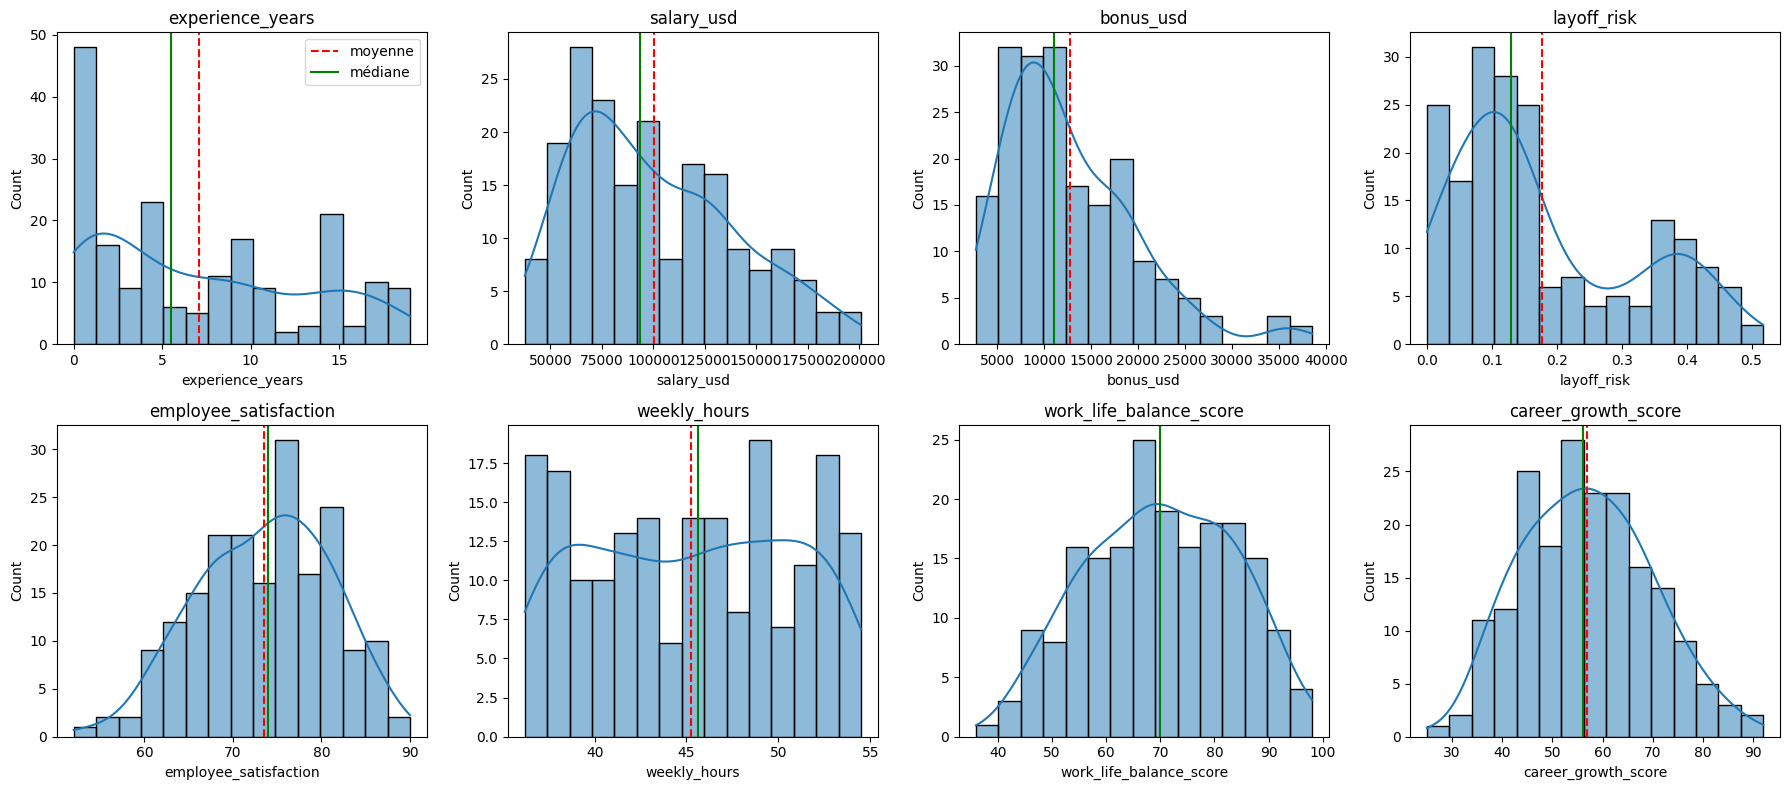

In [29]:
# Histogrammes des 8 variables quantitatives, avec la courbe de densité (kde)
# La ligne rouge = moyenne, la ligne verte = médiane
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, var in zip(axes.ravel(), QUANT):
    sns.histplot(df[var], kde=True, bins=15, ax=ax)
    ax.axvline(df[var].mean(), color="red", linestyle="--", label="moyenne")
    ax.axvline(df[var].median(), color="green", linestyle="-", label="médiane")
    ax.set_title(var)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

### 1.3.1 Interprétation

- `employee_satisfaction`, `career_growth_score` et `work_life_balance_score` ont une forme en cloche, à peu près symétrique.
- `weekly_hours` est presque plate : les offres se répartissent de façon régulière entre 36 h et 55 h par semaine, sans valeur dominante.
- `layoff_risk` a **deux bosses** : la majorité des offres ont un risque faible (la moitié sont sous 0,13), et un second groupe se détache autour de 0,35 à 0,45. Ce second groupe correspond aux offres Entry (leur risque va de 0,26 à 0,52).
- `bonus_usd` et `salary_usd` présentent une queue à droite : quelques offres très bien payées.
- `experience_years` a un pic au début (0 à 2 ans) puis une répartition plate.

## 1.4 Détection des valeurs extrêmes (boxplots)
Un boxplot (boîte à moustaches) résume une variable : la boîte va du 1er au 3e quartile, la ligne au milieu est la médiane. Les points au-delà des moustaches sont des **valeurs extrêmes**.

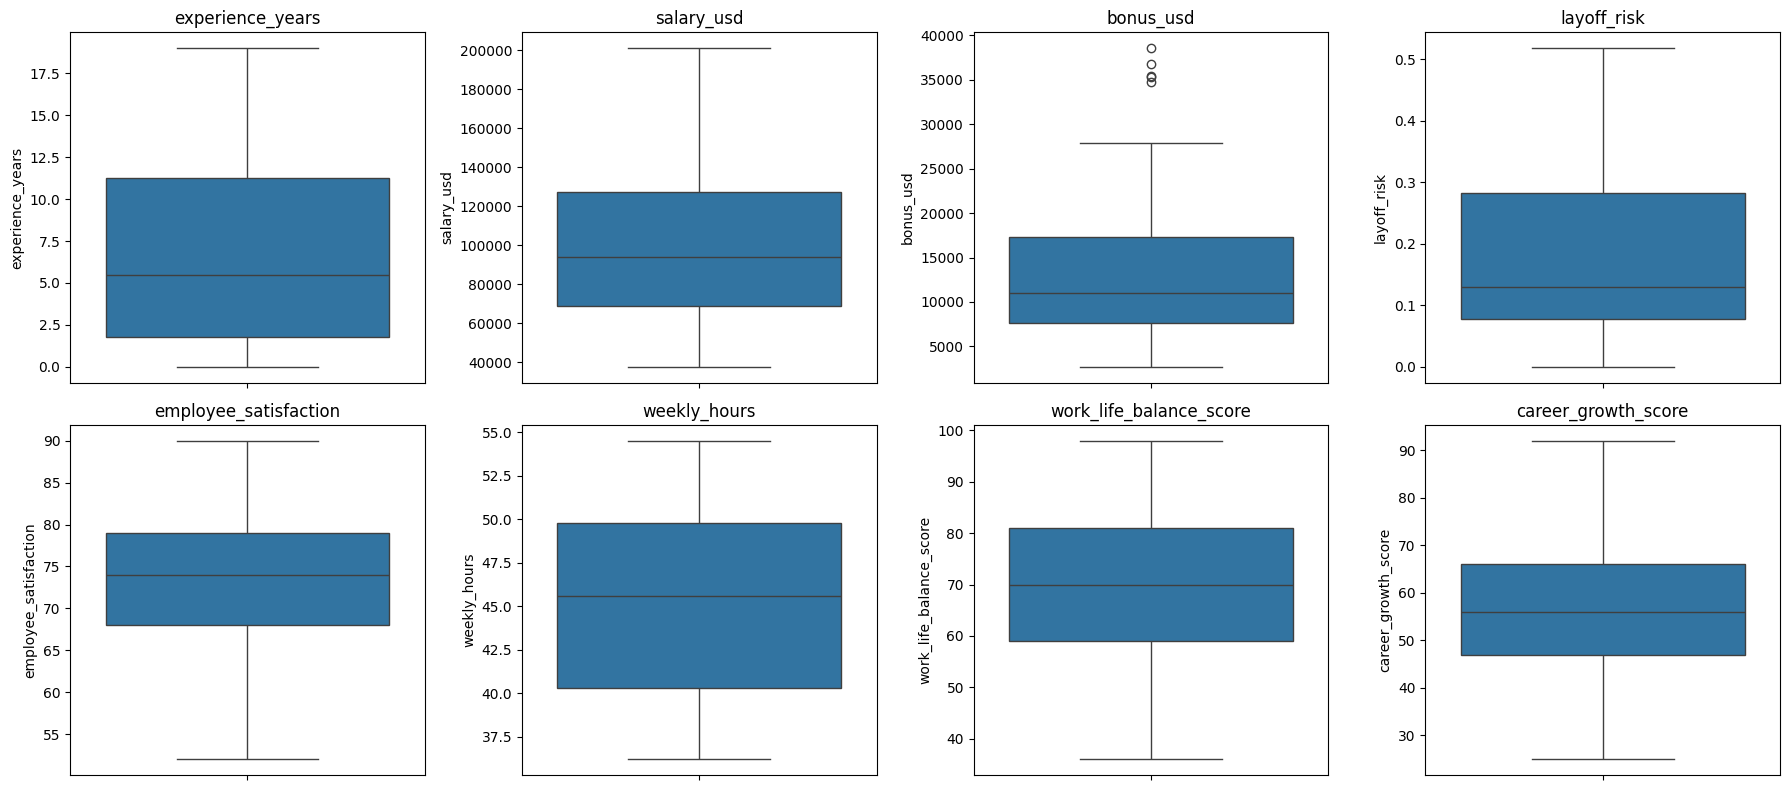

In [30]:
# Un boxplot par variable
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, var in zip(axes.ravel(), QUANT):
    sns.boxplot(y=df[var], ax=ax)
    ax.set_title(var)
plt.tight_layout()
plt.show()


### 1.4.1 Interprétation
Seule la variable `bonus_usd` a des valeurs extrêmes : 5 offres, avec un bonus supérieur à environ 32 500 $. Les 5 sont des offres de niveau **Lead**.

# Étape 2 : Relations entre les variables


## 2.1 Matrice de corrélations


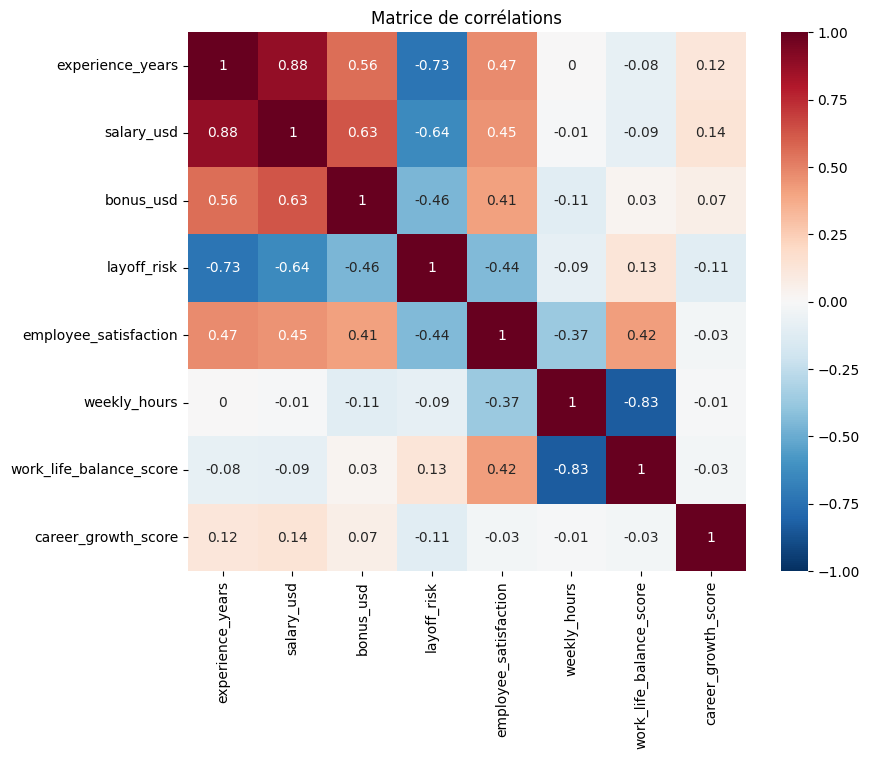

experience_years  salary_usd                 0.88
weekly_hours      work_life_balance_score   -0.83
experience_years  layoff_risk               -0.73
salary_usd        layoff_risk               -0.64
                  bonus_usd                  0.63
experience_years  bonus_usd                  0.56
                  employee_satisfaction      0.47
bonus_usd         layoff_risk               -0.46
dtype: float64

In [12]:
corr = X.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr.round(2), annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélations")
plt.show()

# Les paires les plus corrélées (en valeur absolue)
paires = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
paires = paires.reindex(paires.abs().sort_values(ascending=False).index)
paires.head(8).round(2)

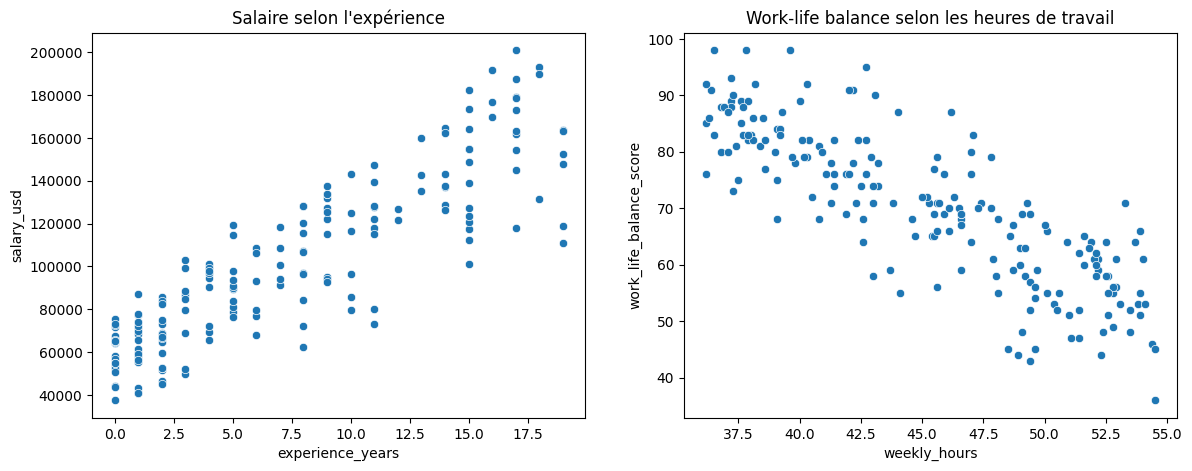

In [21]:
# Deux des liens les plus forts, colorés par niveau d'expérience
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="experience_years", y="salary_usd", ax=axes[0])
axes[0].set_title("Salaire selon l'expérience")
sns.scatterplot(data=df, x="weekly_hours", y="work_life_balance_score", ax=axes[1])
axes[1].set_title("Work-life balance selon les heures de travail")
plt.show()

## 2.2 Interprétation

Les liens les plus forts sont :
- `experience_years` et `salary_usd` : **+0,88**. Plus l'ancienneté est élevée, plus le salaire est élevé.
- `weekly_hours` et `work_life_balance_score` : **-0,83**. Plus on travaille d'heures, plus l'équilibre de vie est mauvais.
- `experience_years` et `layoff_risk` : **-0,73**, et `salary_usd` et `layoff_risk` : **-0,64**. Les offres plus expérimentées et mieux payées ont un risque de licenciement plus faible.
- `salary_usd` et `bonus_usd` : **+0,63**. Le bonus suit le salaire.
- `employee_satisfaction` est liée positivement à l'expérience (+0,47) et au salaire (+0,45), et négativement au risque de licenciement (-0,44).

`career_growth_score` est presque indépendante de toutes les autres variables : elle ne ressemble à aucune autre.

**Ces corrélations annoncent la structure de l'ACP : un groupe « carrière et sécurité », un groupe « équilibre de vie », et `career_growth_score` seule.**

# Étape 3 : Analyse en Composantes Principales (ACP)


## 3.1 Centrage-réduction


In [36]:
n = X.shape[0]    # nombre d'individus
p = X.shape[1]    # nombre de variables

sc = StandardScaler()
Z = sc.fit_transform(X)       # matrice centrée-réduite

# Conversion de la matrice Z (NumPy ndarray) en DataFrame Pandas
Z_df = pd.DataFrame(Z, index=X.index, columns=X.columns)
stats_Z = Z_df.describe()

# Sélectionner la moyenne et l'écart-type, puis transposer pour l'affichage
stats_Z = stats_Z.loc[["mean", "std"]].T
stats_Z.round(2)

,mean,std
experience_years,0.0,1.0
salary_usd,0.0,1.0
bonus_usd,0.0,1.0
layoff_risk,0.0,1.0
employee_satisfaction,-0.0,1.0
weekly_hours,-0.0,1.0
work_life_balance_score,-0.0,1.0
career_growth_score,0.0,1.0


In [40]:
# (1/n) Z'Z est exactement la matrice de corrélations
mat_corr=Z.T @ Z / n
mat_corr = pd.DataFrame(mat_corr, index=X.columns, columns=X.columns)
display(mat_corr.round(2))

,experience_years,salary_usd,bonus_usd,layoff_risk,employee_satisfaction,weekly_hours,work_life_balance_score,career_growth_score
experience_years,1.00,0.88,0.56,-0.73,0.47,0.00,-0.08,0.12
salary_usd,0.88,1.00,0.63,-0.64,0.45,-0.01,-0.09,0.14
bonus_usd,0.56,0.63,1.00,-0.46,0.41,-0.11,0.03,0.07
layoff_risk,-0.73,-0.64,-0.46,1.00,-0.44,-0.09,0.13,-0.11
employee_satisfaction,0.47,0.45,0.41,-0.44,1.00,-0.37,0.42,-0.03
weekly_hours,0.00,-0.01,-0.11,-0.09,-0.37,1.00,-0.83,-0.01
work_life_balance_score,-0.08,-0.09,0.03,0.13,0.42,-0.83,1.00,-0.03
career_growth_score,0.12,0.14,0.07,-0.11,-0.03,-0.01,-0.03,1.00


## 3.2 Valeurs propres et choix du nombre d'axes

In [42]:
acp = PCA()
coord = acp.fit_transform(Z)       # coordonnées factorielles des individus

# scikit-learn divise par n-1 ; la matrice de corrélations divise par n.
# On corrige pour retrouver exactement les valeurs propres de la matrice de corrélations
eigval = acp.explained_variance_ * (n - 1) / n
vect_prop = acp.components_        # vecteurs propres

Prop_inert = eigval / eigval.sum()
cuminert = np.cumsum(Prop_inert) * 100

tab_vp = pd.DataFrame({"valprop": eigval, "Prop_inertie": Prop_inert, "inertiecum": cuminert},
                      index=[f"axe {i+1}" for i in range(p)])
print("Somme des valeurs propres =", round(eigval.sum(), 3), "(= nombre de variables)")
tab_vp.round(3)

Somme des valeurs propres = 8.0 (= nombre de variables)


,valprop,Prop_inertie,inertiecum
axe 1,3.341,0.418,41.756
axe 2,2.068,0.258,67.601
axe 3,0.996,0.125,80.055
axe 4,0.575,0.072,87.243
axe 5,0.428,0.054,92.596
axe 6,0.338,0.042,96.819
axe 7,0.154,0.019,98.746
axe 8,0.100,0.013,100.000


### 3.2.1 Interprétation

- Les valeurs propres sont 3,34 / 2,07 / 0,996 / 0,58... Leur somme est égale à 8, le nombre de variables : c'est l'inertie totale.
- Le 1er axe explique **41,8 %** de l'inertie, le 2e **25,8 %** (cumul **67,6 %**), le 3e **12,5 %** (cumul **80,1 %**).
- **Kaiser** (garder les axes de valeur propre > 1) retiendrait 2 axes, mais le 3e est à 0,996, quasiment à 1.
- **Choix : 3 axes.** Ils cumulent 80 % de l'inertie.

## 3.3 Individus : coordonnées, contributions et qualités de représentation

- **Contribution** d'un individu à un axe : sa part dans la construction de l'axe. Les individus aux plus fortes contributions « fabriquent » l'axe.
- **Qualité de représentation (cos²)** : à quel point un individu est bien représenté sur l'axe. Proche de 100 %, il est bien représenté ; proche de 0 %, il est mal représenté et ne doit pas être interprété sur ce plan.

In [54]:
NB_AXES = 3    # nombre d'axes retenus (justifié en 3.2)

A = coord ** 2
Ctr = (A / (n * eigval)) * 100               # contribution de chaque individu à chaque axe (%)
normind = np.sum(Z ** 2, axis=1)             # distance² de chaque individu au centre du nuage
Cos = (A / normind[:, None]) * 100           # qualité de représentation sur chaque axe (%)

res_ind = pd.DataFrame({"ID": X.index})
for j in range(NB_AXES):
    res_ind[f"Coord_{j+1}"] = coord[:, j]
    res_ind[f"Ctr_{j+1}"] = Ctr[:, j]
    res_ind[f"Cos2_{j+1}"] = Cos[:, j]
res_ind["Cos2_total"] = Cos[:, :NB_AXES].sum(axis=1)   # qualité sur les 3 axes ensemble

print("Somme des contributions par axe (doit faire 100) :", Ctr[:, :NB_AXES].sum(axis=0).round(1))
print("Qualité moyenne sur le plan 1-2 :", round(Cos[:, :2].sum(axis=1).mean(), 1), "%")
print("Qualité moyenne sur les 3 axes  :", round(Cos[:, :3].sum(axis=1).mean(), 1), "%")
#not sure ml critere hedha !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
print("Part des individus bien représentés (cos² total > 50 %) :", round((res_ind["Cos2_total"] > 50).mean() * 100), "%")
res_ind.round(2).head(10)

Somme des contributions par axe (doit faire 100) : [100. 100. 100.]
Qualité moyenne sur le plan 1-2 : 62.2 %
Qualité moyenne sur les 3 axes  : 76.5 %
Part des individus bien représentés (cos² total > 50 %) : 92 %


,ID,Coord_1,Ctr_1,Cos2_1,Coord_2,Ctr_2,Cos2_2,Coord_3,Ctr_3,Cos2_3,Cos2_total
0,56273,-2.54,1.01,49.60,-1.91,0.92,28.02,0.82,0.35,5.13,82.75
1,5318,-1.98,0.61,38.30,2.46,1.53,58.95,0.01,0.00,0.00,97.25
2,24801,-1.89,0.55,45.96,1.79,0.81,41.52,0.47,0.11,2.80,90.27
3,23124,-2.13,0.71,67.93,1.07,0.29,17.04,-0.15,0.01,0.35,85.31
4,68909,-2.39,0.89,84.44,-0.70,0.12,7.33,-0.21,0.02,0.66,92.44
5,51889,-2.18,0.74,65.51,0.67,0.11,6.26,0.30,0.05,1.28,73.05
6,3646,-2.17,0.73,40.36,1.92,0.93,31.58,0.98,0.50,8.27,80.21
7,11136,-2.90,1.31,82.02,0.41,0.04,1.60,0.59,0.18,3.35,86.98
8,61114,-3.42,1.82,83.93,-0.94,0.22,6.34,-0.96,0.48,6.64,96.91
9,47035,-1.56,0.38,33.90,2.05,1.06,58.75,-0.24,0.03,0.81,93.47


In [55]:
# Les 5 individus qui contribuent le plus à l'axe 1
res_ind.sort_values("Ctr_1", ascending=False).round(2).head(5)

,ID,Coord_1,Ctr_1,Cos2_1,Coord_2,Ctr_2,Cos2_2,Coord_3,Ctr_3,Cos2_3,Cos2_total
158,59259,4.65,3.37,68.35,0.76,0.15,1.82,1.93,1.94,11.72,81.90
22,30264,4.52,3.18,82.88,-0.28,0.02,0.31,0.38,0.08,0.60,83.79
68,83839,4.01,2.50,76.22,0.80,0.16,3.06,0.95,0.47,4.24,83.52
67,81901,3.56,1.97,77.33,0.92,0.21,5.19,-1.26,0.82,9.64,92.16
8,61114,-3.42,1.82,83.93,-0.94,0.22,6.34,-0.96,0.48,6.64,96.91


In [56]:
# Les 5 individus qui contribuent le plus à l'axe 2
res_ind.sort_values("Ctr_2", ascending=False).round(2).head(5)

,ID,Coord_1,Ctr_1,Cos2_1,Coord_2,Ctr_2,Cos2_2,Coord_3,Ctr_3,Cos2_3,Cos2_total
89,88359,0.31,0.01,0.75,-3.06,2.35,74.43,0.88,0.41,6.20,81.39
173,79512,-2.10,0.69,31.17,-2.93,2.16,60.64,0.52,0.14,1.92,93.73
166,14449,1.50,0.35,18.32,-2.92,2.15,69.32,-0.40,0.08,1.30,88.94
54,39162,-1.43,0.32,13.17,2.88,2.09,53.69,1.53,1.22,15.11,81.97
65,12861,1.49,0.35,19.21,-2.71,1.85,63.43,0.45,0.11,1.78,84.42


In [57]:
# Les 5 individus qui contribuent le plus à l'axe 3
res_ind.sort_values("Ctr_3", ascending=False).round(2).head(5)

,ID,Coord_1,Ctr_1,Cos2_1,Coord_2,Ctr_2,Cos2_2,Coord_3,Ctr_3,Cos2_3,Cos2_total
79,414,-0.54,0.05,2.72,-1.58,0.63,23.39,2.61,3.55,63.43,89.53
91,72832,1.01,0.16,12.41,-0.17,0.01,0.35,2.31,2.80,65.56,78.33
144,45611,-1.43,0.32,20.59,0.85,0.18,7.20,-2.24,2.63,50.73,78.52
177,64340,-0.91,0.13,13.55,0.12,0.00,0.22,2.15,2.43,75.50,89.27
146,69362,-2.23,0.78,43.10,1.28,0.41,14.09,2.08,2.27,37.46,94.65


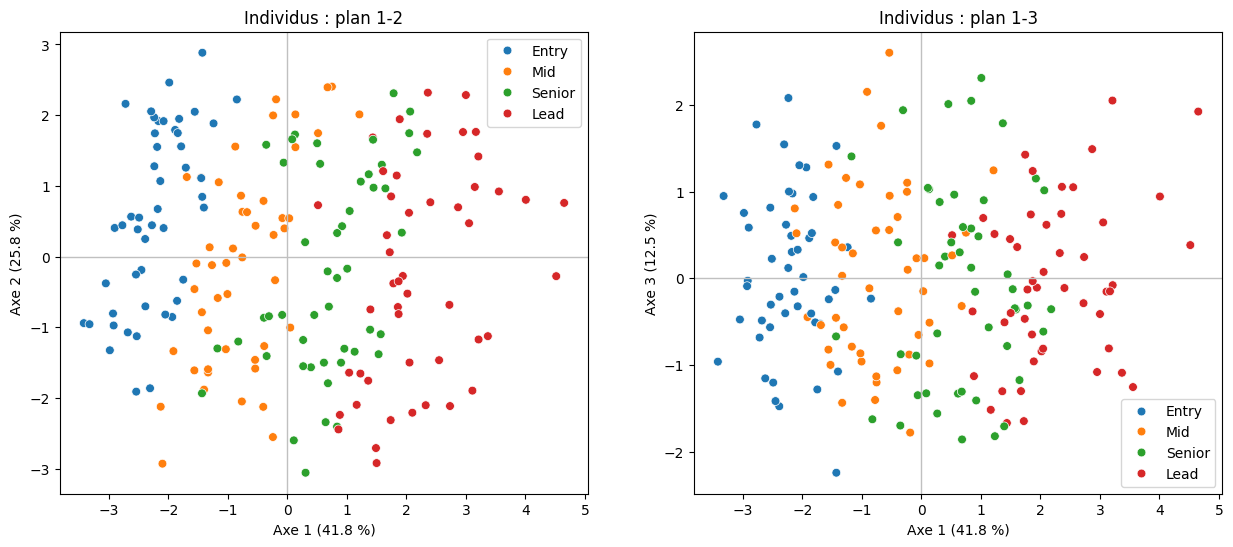

In [70]:
ORDRE_EXP = ["Entry", "Mid", "Senior", "Lead"]

# Projection des individus dans les plans factoriels 1-2 et 1-3, colorés par niveau d'expérience
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2),]):
    sns.scatterplot(x=coord[:, a], y=coord[:, b], hue=df["experience_level"].values,
                    hue_order=ORDRE_EXP, s=40, ax=ax)
    ax.axhline(0, color="silver", lw=1)
    ax.axvline(0, color="silver", lw=1)
    ax.set_xlabel(f"Axe {a+1} ({Prop_inert[a]*100:.1f} %)")
    ax.set_ylabel(f"Axe {b+1} ({Prop_inert[b]*100:.1f} %)")
    ax.set_title(f"Individus : plan {a+1}-{b+1}")
plt.show()

### 3.3.1 Interprétation


- La qualité de représentation moyenne est de 62 % sur le plan 1-2 et de 77 % sur les 3 axes. **92 %** des individus ont un cos² total supérieur à 50 % : la grande majorité est bien représentée.
- Sur le plan 1-2, les niveaux d'expérience se disposent le long de l'**axe 1** : les offres **Entry** à gauche, les **Lead** à droite, **Mid** et **Senior** entre les deux. L'axe 1 est donc un axe de séniorité.
- L'**axe 2** sépare peu les niveaux d'expérience : à chaque niveau, on trouve des offres en haut et en bas (les Entry sont seulement un peu plus souvent en haut). Il mesure donc autre chose que la séniorité.

## 3.4 Variables : cercle des corrélations

Les coordonnées d'une variable sur un axe sont sa **corrélation** avec cet axe. Sur le cercle, une flèche longue et proche du bord est bien représentée ; deux flèches proches sont corrélées positivement, deux flèches opposées négativement, deux flèches à angle droit ne sont pas corrélées.

In [71]:
sqrt_eigval = np.sqrt(eigval)
corvar = vect_prop.T * sqrt_eigval          # corrélations variables-axes (variables en lignes)
Ctrvar = (corvar ** 2) / eigval * 100       # contribution des variables à chaque axe (%)
Cosvar = (corvar ** 2) * 100                # qualité de représentation des variables (%)

res_var = pd.DataFrame({"ID": X.columns})
for j in range(NB_AXES):
    res_var[f"corvar{j+1}"] = corvar[:, j]
    res_var[f"Ctrvar{j+1}"] = Ctrvar[:, j]
    res_var[f"Cosvar{j+1}"] = Cosvar[:, j]
res_var.round(2)

,ID,corvar1,Ctrvar1,Cosvar1,corvar2,Ctrvar2,Cosvar2,corvar3,Ctrvar3,Cosvar3
0,experience_years,0.91,24.80,82.84,-0.17,1.42,2.94,-0.02,0.03,0.03
1,salary_usd,0.90,24.32,81.24,-0.16,1.27,2.63,0.01,0.01,0.01
2,bonus_usd,0.75,16.72,55.84,0.00,0.00,0.00,-0.04,0.16,0.16
3,layoff_risk,-0.80,19.34,64.61,0.23,2.54,5.26,0.04,0.14,0.14
4,employee_satisfaction,0.67,13.45,44.92,0.46,10.20,21.08,-0.15,2.21,2.20
5,weekly_hours,-0.14,0.57,1.91,-0.92,40.59,83.92,-0.11,1.17,1.17
6,work_life_balance_score,0.07,0.13,0.44,0.95,43.57,90.08,0.05,0.27,0.27
7,career_growth_score,0.15,0.67,2.25,-0.09,0.41,0.85,0.98,96.00,95.64


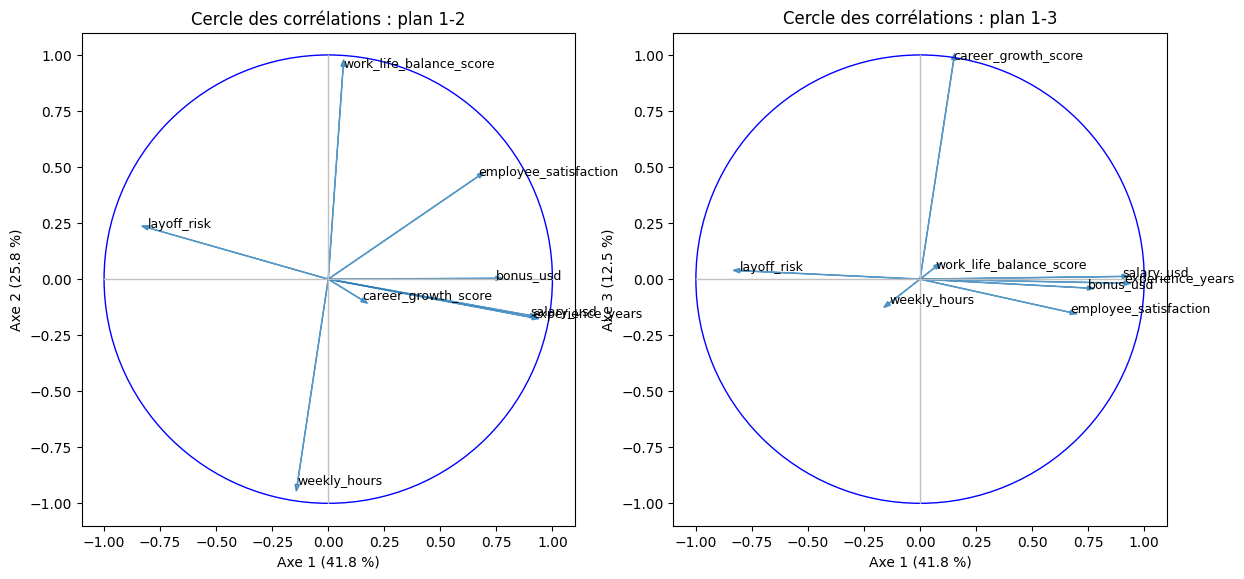

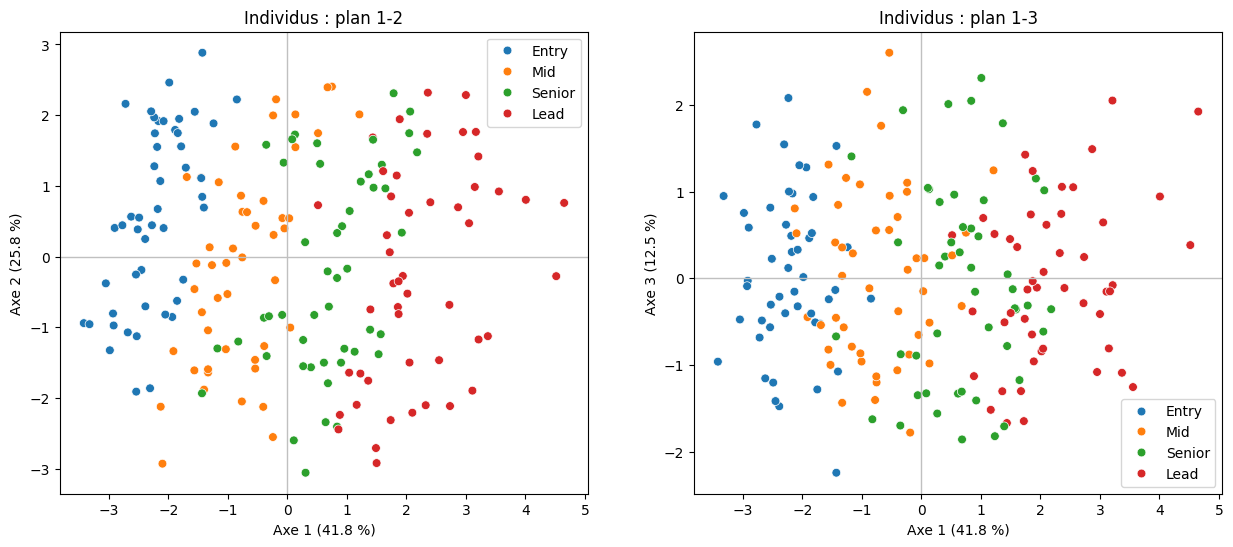

In [73]:
# Cercles des corrélations : plan 1-2 et plan 1-3
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2)]):
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    for j in range(p):
        ax.arrow(0, 0, corvar[j, a], corvar[j, b], head_width=0.02, color="tab:blue", alpha=0.7)
        ax.annotate(X.columns[j], (corvar[j, a], corvar[j, b]), fontsize=9)
    ax.plot([-1, 1], [0, 0], color="silver", lw=1)
    ax.plot([0, 0], [-1, 1], color="silver", lw=1)
    ax.add_artist(plt.Circle((0, 0), 1, color="blue", fill=False))
    ax.set_xlabel(f"Axe {a+1} ({Prop_inert[a]*100:.1f} %)")
    ax.set_ylabel(f"Axe {b+1} ({Prop_inert[b]*100:.1f} %)")
    ax.set_title(f"Cercle des corrélations : plan {a+1}-{b+1}")
    ax.set_aspect("equal")
plt.show()
ORDRE_EXP = ["Entry", "Mid", "Senior", "Lead"]

# Projection des individus dans les plans factoriels 1-2 et 1-3, colorés par niveau d'expérience
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2),]):
    sns.scatterplot(x=coord[:, a], y=coord[:, b], hue=df["experience_level"].values,
                    hue_order=ORDRE_EXP, s=40, ax=ax)
    ax.axhline(0, color="silver", lw=1)
    ax.axvline(0, color="silver", lw=1)
    ax.set_xlabel(f"Axe {a+1} ({Prop_inert[a]*100:.1f} %)")
    ax.set_ylabel(f"Axe {b+1} ({Prop_inert[b]*100:.1f} %)")
    ax.set_title(f"Individus : plan {a+1}-{b+1}")
plt.show()

### 3.4.1 Interprétation

**Axe 1 (41,8 %) :**
- Corrélations positives : `experience_years` (0,91), `salary_usd` (0,90), `bonus_usd` (0,75), `employee_satisfaction` (0,67).
- Corrélation négative : `layoff_risk` (-0,80).
- Contributions : `experience_years` 25 %, `salary_usd` 24 %, `layoff_risk` 19 %, `bonus_usd` 17 %.
- Plus on va vers la droite de l'axe, plus les offres sont anciennes, bien payées, satisfaisantes, et sûres.

**➡cet axe reprsente :ancienneté, rémunération et sécurité**

**Axe 2 (25,8 %) :**
- `work_life_balance_score` (+0,95) s'oppose à `weekly_hours` (-0,92). Ces deux variables contribuent à 44 % et 41 %. `employee_satisfaction` suit un peu (+0,46).
- Plus on monte, plus l'équilibre de vie est bon et les heures sont courtes.

**➡cet axe reprsente : équilibre de vie**


**Axe 3 (12,5 %) : `career_growth_score`** seule (corrélation 0,98, contribution 96 %). Elle est indépendante des autres variables.

**Lecture croisée :**  Les axes 1 et 2 sont orthogonaux : la séniorité et l'équilibre de vie sont deux dimensions indépendantes.
- On le voit aussi dans les corrélations : le salaire et les heures de travail ne sont pratiquement pas liés (-0,01).
- Les variables `experience_years` et `salary_usd` sont presque superposées sur le cercle : elles apportent quasiment la même information.

# Étape 4 : Classification Ascendante Hiérarchique (CAH)


## 4.1 Construction de l'arbre et choix du nombre de classes

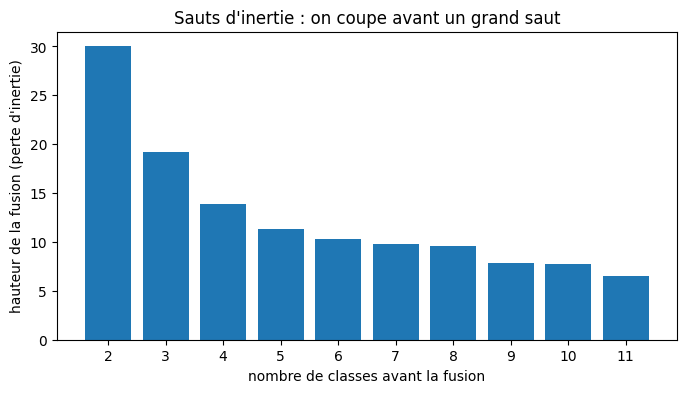

,inertie expliquée (%)
k,
2,29.3
3,41.4
4,47.7
5,51.8
6,55.3
7,58.4
8,61.4


In [80]:
# Matrice des liens : méthode de Ward, distance euclidienne
Zl = linkage(Z, method="ward", metric="euclidean")

# Hauteur des 10 dernières fusions (la plus haute = la dernière, de 2 classes à 1)
hauteurs = Zl[-10:, 2][::-1]
ks = list(range(2, 12))      # hauteurs[i] = fusion qui passe de (i+2) classes à (i+1)

plt.figure(figsize=(8, 4))
plt.bar(ks, hauteurs)
plt.xticks(ks)
plt.xlabel("nombre de classes avant la fusion")
plt.ylabel("hauteur de la fusion (perte d'inertie)")
plt.title("Sauts d'inertie : on coupe avant un grand saut")
plt.show()

# Pourcentage d'inertie expliquée par la partition en k classes
inertie_totale = (Z ** 2).sum()
resume = []
for k in range(2, 9):
    g = fcluster(Zl, t=k, criterion="maxclust")
    intra = sum(((Z[g == c] - Z[g == c].mean(axis=0)) ** 2).sum() for c in np.unique(g))
    resume.append({"k": k, "inertie expliquée (%)": round((1 - intra / inertie_totale) * 100, 1)})
pd.DataFrame(resume).set_index("k")

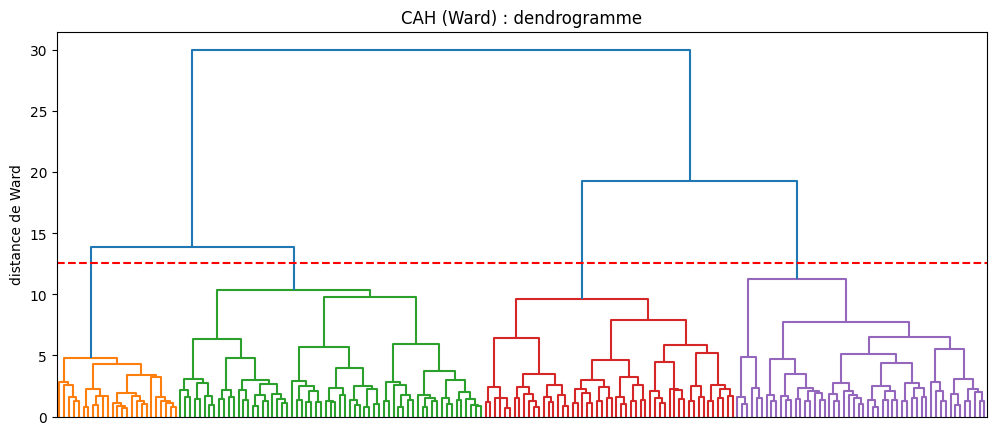

Effectifs par classe :
1    25
2    63
3    52
4    52
Name: count, dtype: int64


In [81]:
K_CHOISI = 4    # nombre de classes retenu (justifié ci-dessous)

# Seuil de coupure : entre la fusion K->K-1 et la fusion (K+1)->K
seuil = (Zl[-(K_CHOISI - 1), 2] + Zl[-K_CHOISI, 2]) / 2

plt.figure(figsize=(12, 5))
plt.title("CAH (Ward) : dendrogramme")
dendrogram(Zl, no_labels=True, color_threshold=seuil)    # 192 feuilles : on cache les étiquettes
plt.axhline(seuil, color="red", linestyle="--")
plt.ylabel("distance de Ward")
plt.show()

groupes_cah = fcluster(Zl, t=K_CHOISI, criterion="maxclust")   # numéro de classe de chaque individu
print("Effectifs par classe :")
print(pd.Series(groupes_cah).value_counts().sort_index())

### 4.1 Interprétation

- Les sauts d'inertie diminuent régulièrement (30, 19, 14, 11, 10...) : il n'y a pas de coude net. Le plus grand saut se fait de de 3 à 2.
- Le pourcentage d'inertie expliquée progresse lentement : 29 % à 2 classes, 41 % à 3, **48 % à 4**, 52 % à 5, 55 % à 6.

- **➡ Choix : 4 classes :**
C'est un bon compromis entre la simplicité et l'information : au-delà de 4 classes, chaque classe supplémentaire n'apporte plus que 3 à 4 points d'inertie. Et surtout, les 4 classes sont **interprétables** (voir 4.2) et correspondent à la structure des axes 1 et 2 de l'ACP.
- Les effectifs (25, 63, 52 et 52) sont raisonnablement équilibrés.

## 4.2 Caractérisation des classes

,experience_years,salary_usd,bonus_usd,layoff_risk,employee_satisfaction,weekly_hours,work_life_balance_score,career_growth_score
Classe,,,,,,,,
1,0.72,62722.04,8842.44,0.36,72.16,39.62,82.80,54.08
2,2.56,70992.98,8212.68,0.26,67.86,48.37,64.13,56.57
3,10.31,117457.04,15251.75,0.10,80.21,39.92,82.23,58.81
4,12.38,136225.42,17454.40,0.07,74.33,49.41,58.71,56.54


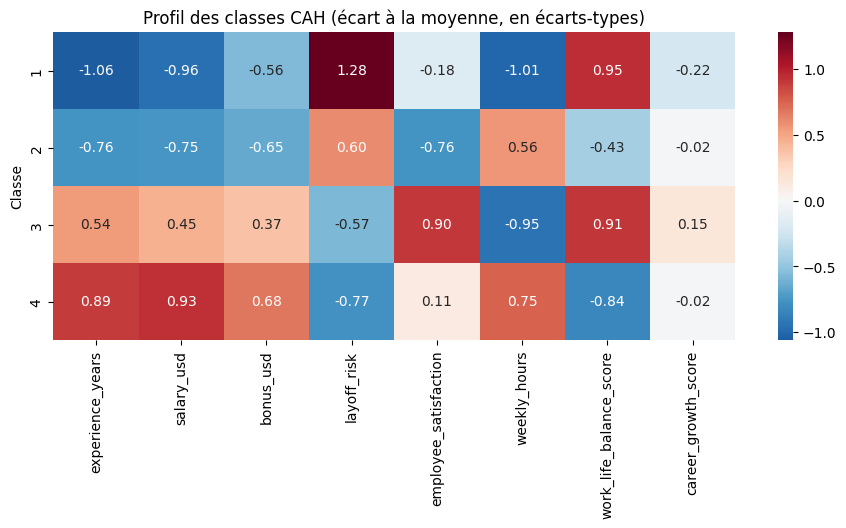

In [82]:
# Moyenne de chaque variable par classe
cl = X.copy()
cl["Classe"] = groupes_cah
gr = cl.groupby("Classe")
display(gr.mean().round(2))

# Même tableau en écarts à la moyenne générale, en écarts-types : plus facile à lire
ecarts = (gr.mean() - X.mean()) / X.std()
plt.figure(figsize=(11, 4))
sns.heatmap(ecarts.round(2), annot=True, cmap="RdBu_r", center=0, fmt=".2f")
plt.title("Profil des classes CAH (écart à la moyenne, en écarts-types)")
plt.show()

In [87]:
####################menich sur bch n5aleha hedhi n7essha zeyda ##############################
# Composition de chaque classe par niveau d'expérience
pd.crosstab(groupes_cah, df["experience_level"])[ORDRE_EXP]

experience_level,Entry,Mid,Senior,Lead
row_0,,,,
1,21,4,0,0
2,27,28,8,0
3,0,12,21,19
4,0,4,19,29


### 4.2.1 Interprétation


#Comparaison des distributions selon les variables qualitatives


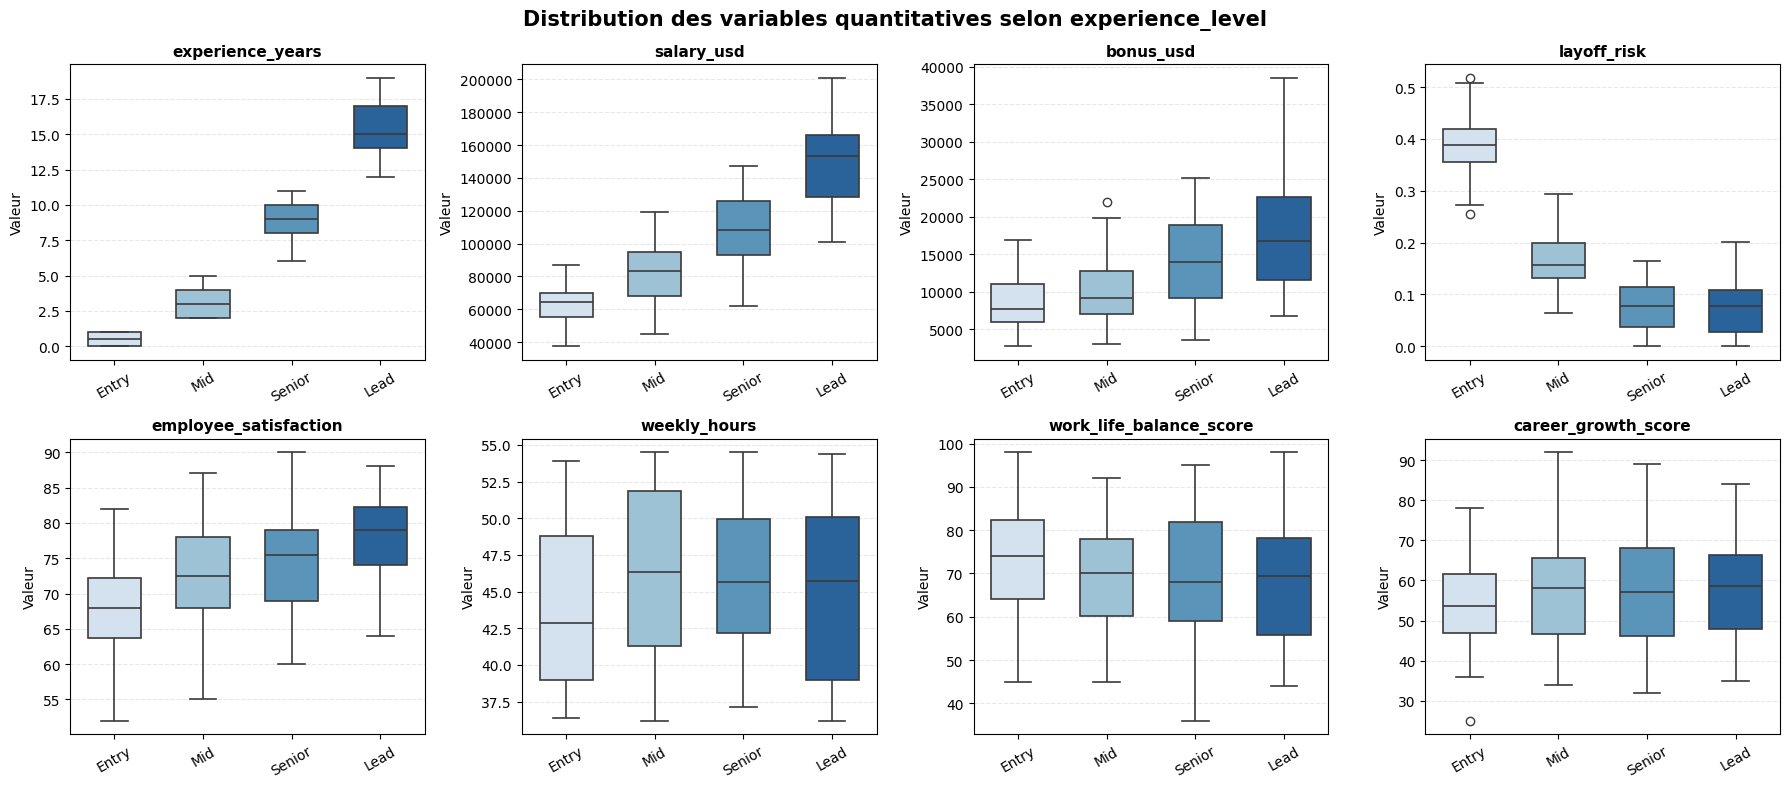

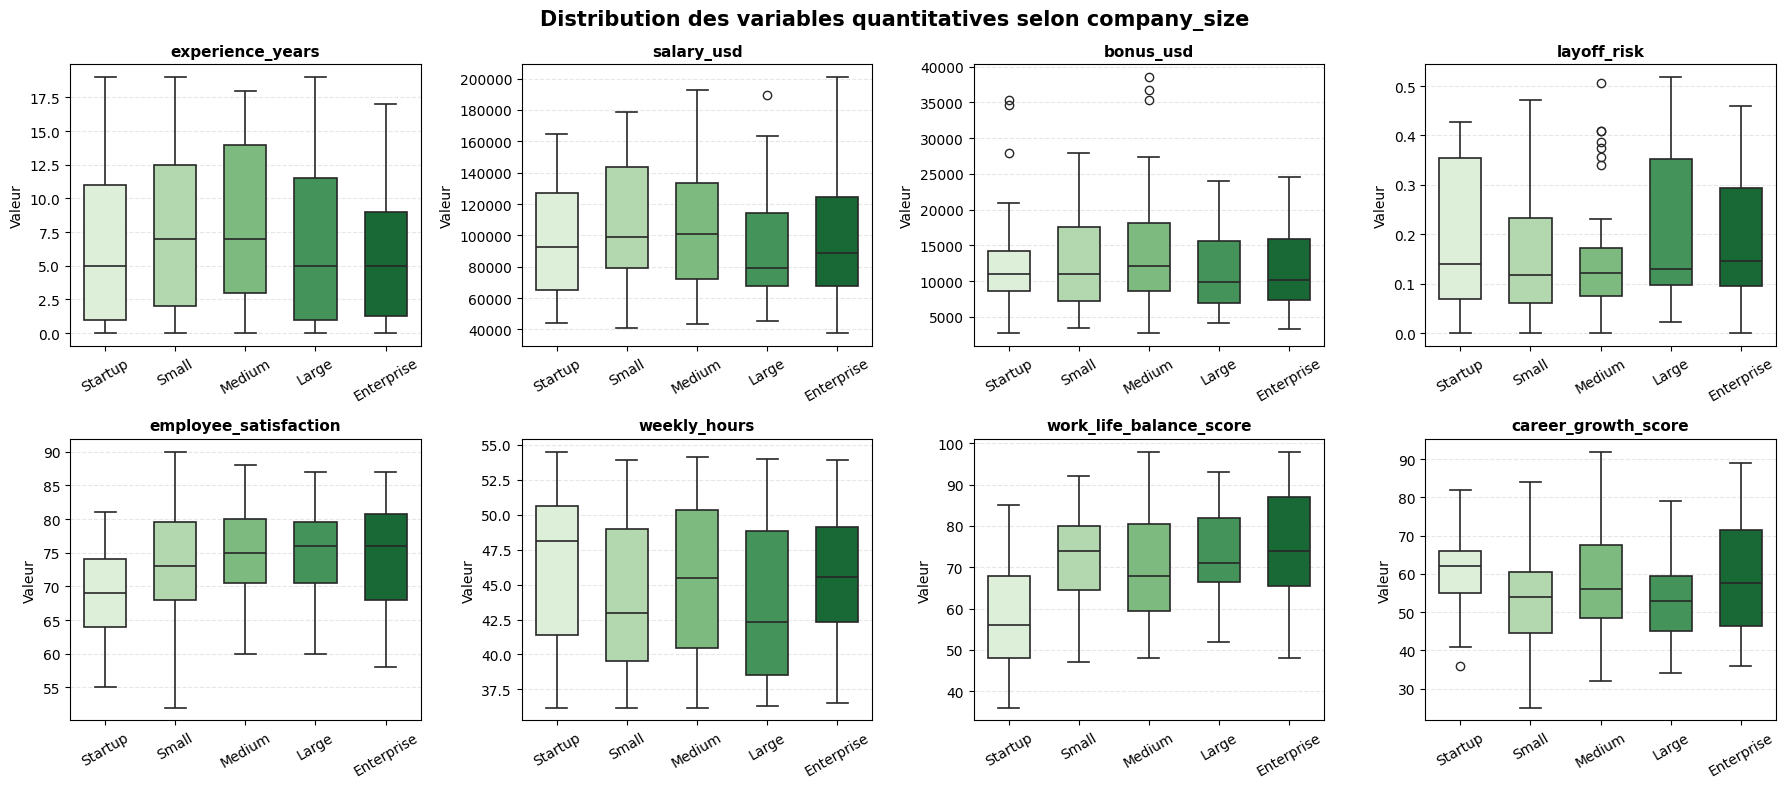

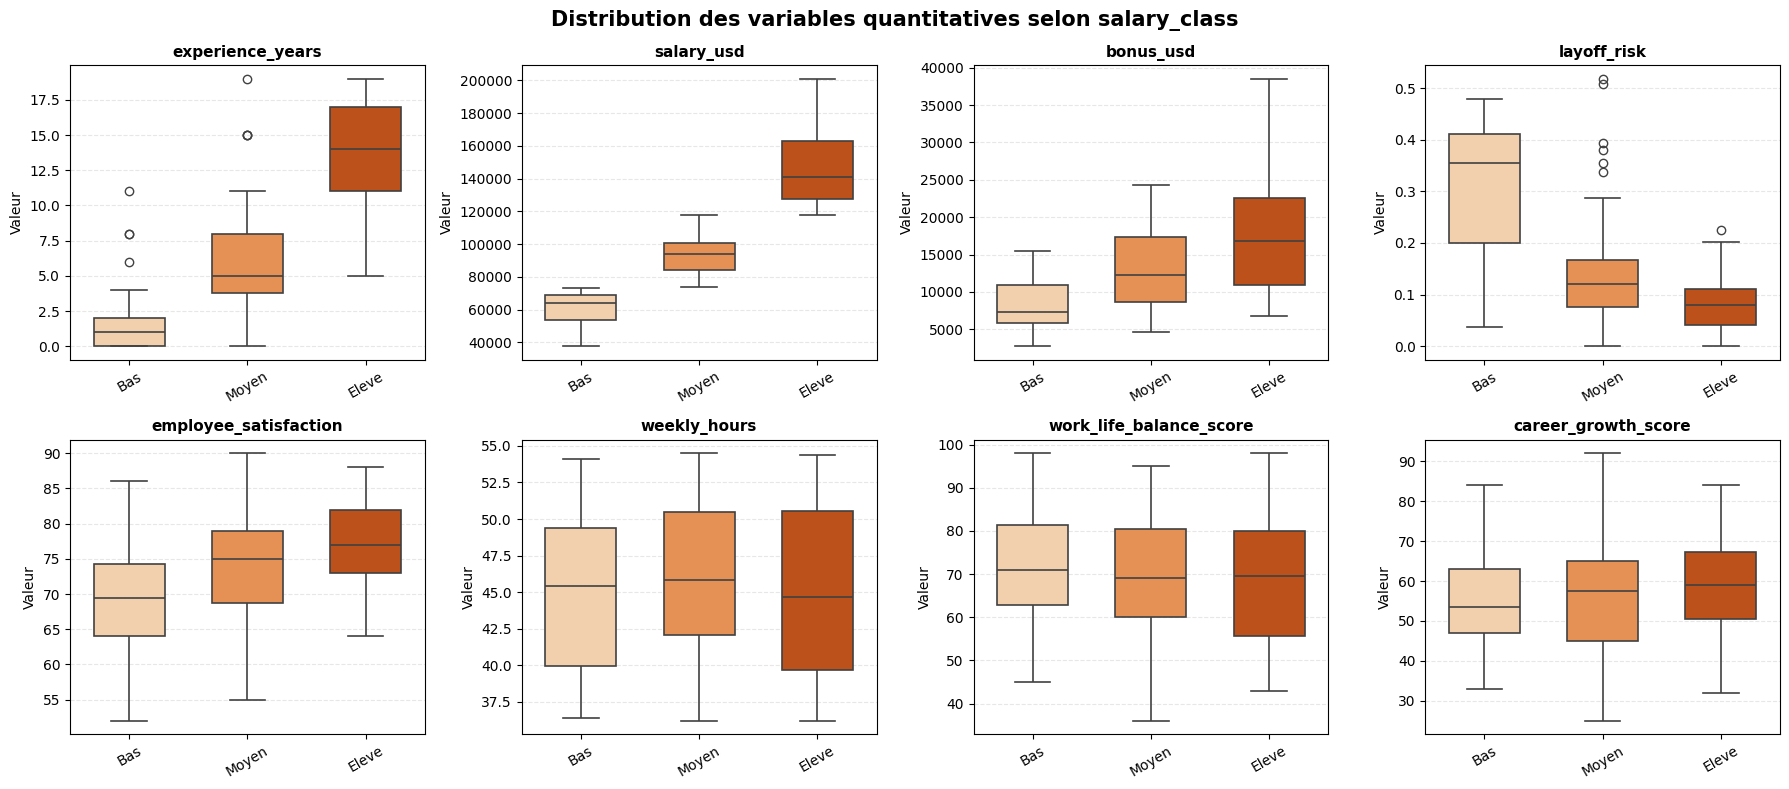

TypeError: boxplots_par() takes 1 positional argument but 2 were given

In [18]:
ORDRE = {
    "experience_level": ["Entry", "Mid", "Senior", "Lead"],
    "company_size": ["Startup", "Small", "Medium", "Large", "Enterprise"],
    "salary_class": ["Bas", "Moyen", "Eleve"],
    "wlb_class": ["Faible", "Moyen", "Elevé"]
}


PALETTES = {
    "experience_level": sns.color_palette("Blues", 4),
        "salary_class": sns.color_palette("Oranges", 3),
    "company_size": sns.color_palette("Greens", 5),
    "wlb_class": sns.color_palette("Reds", 3)
}


def boxplots_par(qual):
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))

    palette = dict(zip(ORDRE[qual], PALETTES[qual]))

    for ax, var in zip(axes.ravel(), QUANT):
        sns.boxplot(
            data=df,
            x=qual,
            y=var,
            order=ORDRE[qual],
            palette=palette,
            hue=qual,
            legend=False,
            ax=ax,
            width=0.6,
            linewidth=1.2
        )

        ax.set_title(var, fontsize=11, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Valeur")
        ax.tick_params(axis="x", rotation=30)
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

    # Hide unused subplots
    for ax in axes.ravel()[len(QUANT):]:
        ax.set_visible(False)

    fig.suptitle(
        "Distribution des variables quantitatives selon " + qual,
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

boxplots_par("experience_level")
boxplots_par("company_size")
boxplots_par("salary_class")
# wlb_class : on retire work_life_balance_score (comparaison circulaire)
boxplots_par("wlb_class", [v for v in QUANT if v != "work_life_balance_score"])

""" I WILL DELETE THIS TEXT LATER """

Noor : j'ai ajouter les Boxplots par wlb_class CAR: c'est quand même utile pour les autres variables. Elle montre si un bon équilibre de vie va avec moins d'heures et plus de satisfaction. Le test de Kruskal-Wallis est très significatif pour weekly_hours (p < 0,0001) et pour employee_satisfaction (p < 0,0001). C'est aussi cohérent avec ta régression, où le work-life balance est la variable la plus importante pour la satisfaction.

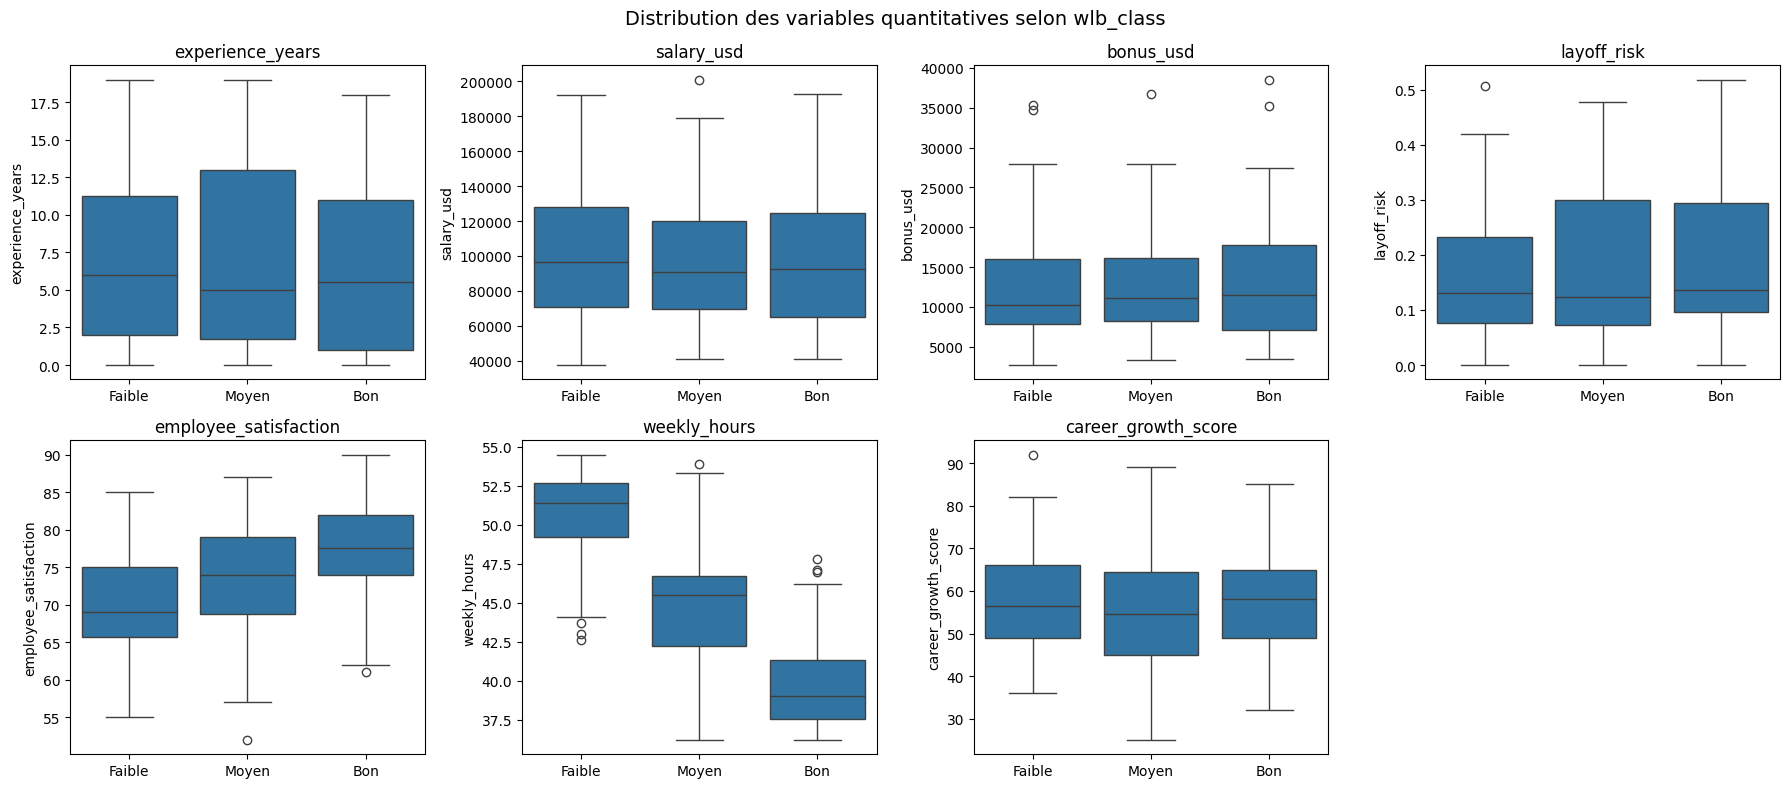

In [ ]:

# On exclut work_life_balance_score : wlb_class en est issue (comparaison circulaire)
VARS = [v for v in QUANT if v != "work_life_balance_score"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, var in zip(axes.ravel(), VARS):
    sns.boxplot(data=df, x="wlb_class", y=var, order=ORDRE["wlb_class"], ax=ax)
    ax.set_title(var)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")   # 7 variables
fig.suptitle("Distribution des variables quantitatives selon wlb_class", fontsize=14)
plt.tight_layout()
plt.show()

## Médianes par groupe et test de Kruskal-Wallis


Cette cellule répond à une seule question : est-ce que chaque variable change vraiment d'un groupe à l'autre ?

Pourquoi seulement ces 2 qualitatives ?

Le sujet du projet pose deux questions précises : « salaire, risque et satisfaction changent-ils selon l'expérience ? » et « le work-life balance change-t-il selon la taille de l'entreprise ? ». Ces deux cellules y répondent directement.


In [ ]:
print("Médianes selon le niveau d'expérience :")
display(df.groupby("experience_level")[QUANT].median().loc[ORDRE["experience_level"]].round(2))

print("Médianes selon la taille de l'entreprise :")
display(df.groupby("company_size")[QUANT].median().loc[ORDRE["company_size"]].round(2))

# Test de Kruskal-Wallis
lignes = []
for var in QUANT:
    p_exp = stats.kruskal(*[g[var] for _, g in df.groupby("experience_level")]).pvalue
    p_size = stats.kruskal(*[g[var] for _, g in df.groupby("company_size")]).pvalue
    lignes.append({"variable": var, "p_experience_level": p_exp, "p_company_size": p_size})
kw = pd.DataFrame(lignes).set_index("variable")
display(kw.round(4))

Médianes selon le niveau d'expérience :


,experience_years,salary_usd,bonus_usd,layoff_risk,employee_satisfaction,weekly_hours,work_life_balance_score,career_growth_score
experience_level,,,,,,,,
Entry,0.5,64549.5,7664.5,0.39,68.0,42.85,74.0,53.5
Mid,3.0,83087.5,9171.0,0.16,72.5,46.35,70.0,58.0
Senior,9.0,108505.5,13948.5,0.08,75.5,45.65,68.0,57.0
Lead,15.0,153330.5,16746.0,0.08,79.0,45.70,69.5,58.5


Médianes selon la taille de l'entreprise :


,experience_years,salary_usd,bonus_usd,layoff_risk,employee_satisfaction,weekly_hours,work_life_balance_score,career_growth_score
company_size,,,,,,,,
Startup,5.0,92781.0,10925.0,0.14,69.0,48.10,56.0,62.0
Small,7.0,99052.0,11030.0,0.12,73.0,43.00,74.0,54.0
Medium,7.0,100935.0,12044.0,0.12,75.0,45.50,68.0,56.0
Large,5.0,79470.0,9892.0,0.13,76.0,42.30,71.0,53.0
Enterprise,5.0,88762.0,10127.5,0.14,76.0,45.55,74.0,57.5


,p_experience_level,p_company_size
variable,,
experience_years,0.0000,0.5835
salary_usd,0.0000,0.2586
bonus_usd,0.0000,0.5030
layoff_risk,0.0000,0.3439
employee_satisfaction,0.0000,0.0035
weekly_hours,0.2218,0.2748
work_life_balance_score,0.3792,0.0000
career_growth_score,0.4953,0.0383


## Interpretation

# Étape 3 : Analyse des Correspondances Multiples (ACM)


In [ ]:
D = pd.get_dummies(df[QUALI]).astype(float)
n = D.shape[0]          # individus
Q = len(QUALI)          # variables qualitatives
p = D.shape[1]          # modalités
K = p - Q               # nombre d'axes non triviaux
print("Tableau disjonctif :", D.shape)
print("Nombre de modalités :", p, "| nombre d'axes :", K)
display(D.head())

Tableau disjonctif : (192, 15)
Nombre de modalités : 15 | nombre d'axes : 11


,experience_level_Entry,experience_level_Lead,experience_level_Mid,experience_level_Senior,salary_class_Bas,salary_class_Eleve,salary_class_Moyen,company_size_Enterprise,company_size_Large,company_size_Medium,company_size_Small,company_size_Startup,wlb_class_Bon,wlb_class_Faible,wlb_class_Moyen
id,,,,,,,,,,,,,,,
56273,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
5318,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
24801,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
23124,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
68909,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
# 3.2 AFC du tableau disjonctif
P = D.values / (n * Q)                 # table de fréquences
r = P.sum(axis=1)                      # masses des individus
c = P.sum(axis=0)                      # masses des modalités
S = (P - np.outer(r, c)) / np.sqrt(np.outer(r, c))
U, sv, Vt = np.linalg.svd(S, full_matrices=False)

eigval = (sv ** 2)[:K]                 # valeurs propres
inertie = eigval / eigval.sum() * 100
print("Inertie totale =", round(eigval.sum(), 4), "(= (p - Q) / Q)")

Inertie totale = 2.75 (= (p - Q) / Q)


## 3.3 Valeurs propres et choix du nombre d'axes


Deux critères : le **coude** des valeurs propres et la **règle de Benzécri** (on garde les axes dont la valeur propre dépasse la moyenne 1/Q, puis on corrige les pourcentages d'inertie).

Seuil 1/Q = 0.25


,valprop,inertie_%,inertie_cum_%,Benzecri_%,Benzecri_cum_%
Axe 1,0.474,17.222,17.222,66.269,66.269
Axe 2,0.374,13.614,30.836,20.504,86.773
Axe 3,0.338,12.280,43.116,10.194,96.967
Axe 4,0.295,10.742,53.858,2.732,99.699
Axe 5,0.265,9.639,63.497,0.301,100.000
Axe 6,0.243,8.843,72.340,0.000,100.000
Axe 7,0.237,8.608,80.948,0.000,100.000
Axe 8,0.205,7.449,88.397,0.000,100.000
Axe 9,0.161,5.846,94.243,0.000,100.000
Axe 10,0.118,4.293,98.536,0.000,100.000


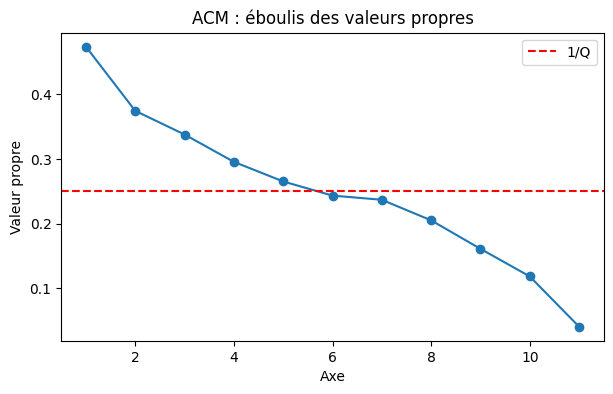

In [ ]:
seuil = 1 / Q
benz = np.where(eigval > seuil, ((Q / (Q - 1)) * (eigval - seuil)) ** 2, 0)
benz_pct = benz / benz.sum() * 100

tab_vp = pd.DataFrame({
    "valprop": eigval,
    "inertie_%": inertie,
    "inertie_cum_%": np.cumsum(inertie),
    "Benzecri_%": benz_pct,
    "Benzecri_cum_%": np.cumsum(benz_pct),
}, index=[f"Axe {i+1}" for i in range(K)])
print("Seuil 1/Q =", seuil)
display(tab_vp.round(3))

plt.figure(figsize=(7, 4))
plt.plot(range(1, K + 1), eigval, marker="o")
plt.axhline(seuil, color="red", linestyle="--", label="1/Q")
plt.xlabel("Axe")
plt.ylabel("Valeur propre")
plt.title("ACM : éboulis des valeurs propres")
plt.legend()
plt.show()

In [ ]:
# 3.4 Coordonnées, contributions et qualités de représentation des modalités
F = (Vt.T / np.sqrt(c)[:, None]) * sv          # coordonnées des modalités
F = F[:, :K]

ctr = (c[:, None] * F ** 2) / eigval * 100     # contributions (%) à chaque axe
cos2 = F ** 2 / (F ** 2).sum(axis=1, keepdims=True) * 100   # qualité de représentation (%)

res = pd.DataFrame({
    "Coord_1": F[:, 0], "Coord_2": F[:, 1],
    "Contr_1": ctr[:, 0], "Contr_2": ctr[:, 1],
    "Cos2_1": cos2[:, 0], "Cos2_2": cos2[:, 1],
}, index=D.columns)
res["Cos2_plan"] = res["Cos2_1"] + res["Cos2_2"]
pd.set_option("display.max_rows", None)
display(res.round(2))

# Modalités qui contribuent plus que la moyenne (100/p %)
print("Contribution moyenne =", round(100 / p, 2), "%")
print("\nModalités importantes pour l'axe 1 :")
print(res.loc[res.Contr_1 > 100 / p, ["Coord_1", "Contr_1", "Cos2_1"]].round(2))
print("\nModalités importantes pour l'axe 2 :")
print(res.loc[res.Contr_2 > 100 / p, ["Coord_2", "Contr_2", "Cos2_2"]].round(2))

,Coord_1,Coord_2,Contr_1,Contr_2,Cos2_1,Cos2_2,Cos2_plan
experience_level_Entry,-1.17,0.96,17.99,15.45,45.44,30.85,76.28
experience_level_Lead,1.29,0.74,22.02,9.22,55.63,18.42,74.05
experience_level_Mid,-0.51,-0.98,3.45,16.17,8.72,32.28,41.00
experience_level_Senior,0.39,-0.72,1.98,8.68,4.99,17.34,22.33
salary_class_Bas,-1.09,0.67,20.99,10.08,59.64,22.64,82.28
salary_class_Eleve,1.22,0.53,26.02,6.27,73.95,14.07,88.03
salary_class_Moyen,-0.12,-1.20,0.27,32.23,0.77,72.40,73.17
company_size_Enterprise,-0.34,0.02,1.24,0.00,2.93,0.01,2.94
company_size_Large,-0.40,0.02,1.75,0.00,4.16,0.01,4.17
company_size_Medium,0.41,-0.13,1.98,0.25,4.82,0.48,5.30


Contribution moyenne = 6.67 %

Modalités importantes pour l'axe 1 :
                        Coord_1  Contr_1  Cos2_1
experience_level_Entry    -1.17    17.99   45.44
experience_level_Lead      1.29    22.02   55.63
salary_class_Bas          -1.09    20.99   59.64
salary_class_Eleve         1.22    26.02   73.95

Modalités importantes pour l'axe 2 :
                         Coord_2  Contr_2  Cos2_2
experience_level_Entry      0.96    15.45   30.85
experience_level_Lead       0.74     9.22   18.42
experience_level_Mid       -0.98    16.17   32.28
experience_level_Senior    -0.72     8.68   17.34
salary_class_Bas            0.67    10.08   22.64
salary_class_Moyen         -1.20    32.23   72.40


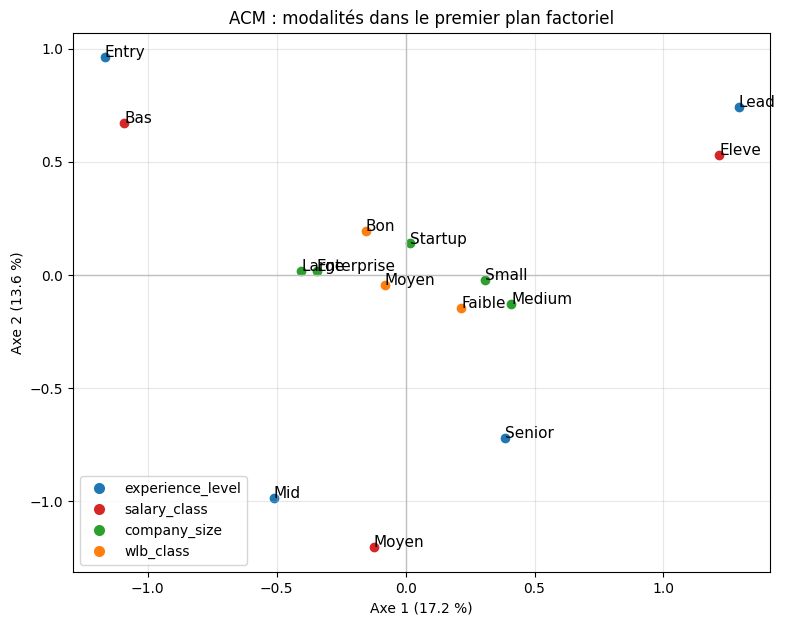

In [ ]:
# 3.5 Représentation des modalités dans le premier plan factoriel
couleurs = {"experience_level": "tab:blue", "salary_class": "tab:red",
            "company_size": "tab:green", "wlb_class": "tab:orange"}

plt.figure(figsize=(9, 7))
for i, modalite in enumerate(D.columns):
    var = next(v for v in QUALI if modalite.startswith(v))
    plt.scatter(F[i, 0], F[i, 1], color=couleurs[var])
    plt.annotate(modalite.replace(var + "_", ""), (F[i, 0], F[i, 1]), fontsize=11)
plt.axhline(0, color="silver", linewidth=1)
plt.axvline(0, color="silver", linewidth=1)
plt.xlabel(f"Axe 1 ({inertie[0]:.1f} %)")
plt.ylabel(f"Axe 2 ({inertie[1]:.1f} %)")
plt.title("ACM : modalités dans le premier plan factoriel")
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=col, markersize=9, label=v)
           for v, col in couleurs.items()]
plt.legend(handles=handles)
plt.grid(True, alpha=0.3)
plt.show()

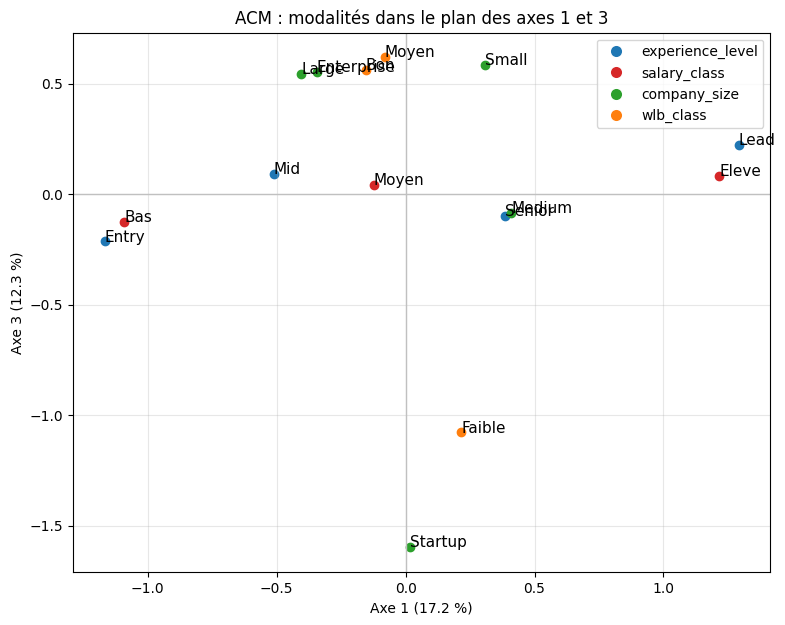

Modalités importantes pour l'axe 3 :
                      Coord_3  Contr_3  Cos2_3
company_size_Startup    -1.60    36.41   60.92
wlb_class_Bon            0.56     7.84   15.89
wlb_class_Faible        -1.08    30.47   63.73
wlb_class_Moyen          0.62     8.90   17.49


In [ ]:
# 3.6 Représentation dans le plan des axes 1 et 3 (la taille d'entreprise et le work-life balance apparaissent sur l'axe 3)
plt.figure(figsize=(9, 7))
for i, modalite in enumerate(D.columns):
    var = next(v for v in QUALI if modalite.startswith(v))
    plt.scatter(F[i, 0], F[i, 2], color=couleurs[var])
    plt.annotate(modalite.replace(var + "_", ""), (F[i, 0], F[i, 2]), fontsize=11)
plt.axhline(0, color="silver", linewidth=1)
plt.axvline(0, color="silver", linewidth=1)
plt.xlabel(f"Axe 1 ({inertie[0]:.1f} %)")
plt.ylabel(f"Axe 3 ({inertie[2]:.1f} %)")
plt.title("ACM : modalités dans le plan des axes 1 et 3")
plt.legend(handles=handles)
plt.grid(True, alpha=0.3)
plt.show()

print("Modalités importantes pour l'axe 3 :")
print(pd.DataFrame({"Coord_3": F[:, 2], "Contr_3": ctr[:, 2], "Cos2_3": cos2[:, 2]}, index=D.columns)
      .loc[ctr[:, 2] > 100 / p].round(2))

##Interprétation


#Classification par k-means


In [ ]:
# 4.1 Standardisation
Z = StandardScaler().fit_transform(df[QUANT])
print(Z.shape)

(192, 8)


## 4.2 Choix du nombre de classes : coude (inertie intra-classes) et silhouette

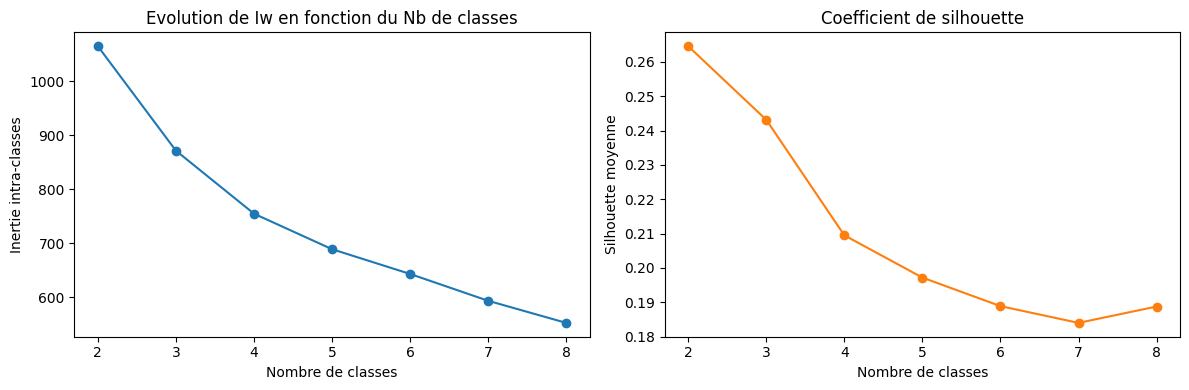

,k,inertie_intra,silhouette
0,2,1065.332,0.265
1,3,871.769,0.243
2,4,755.008,0.210
3,5,689.191,0.197
4,6,643.336,0.189
5,7,593.613,0.184
6,8,552.658,0.189


In [ ]:
inertie_intra, silhouettes = [], []
valeurs_k = range(2, 9)
for k in valeurs_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inertie_intra.append(km.inertia_)
    silhouettes.append(silhouette_score(Z, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(valeurs_k, inertie_intra, marker="o")
axes[0].set_title("Evolution de Iw en fonction du Nb de classes")
axes[0].set_xlabel("Nombre de classes")
axes[0].set_ylabel("Inertie intra-classes")
axes[1].plot(valeurs_k, silhouettes, marker="o", color="tab:orange")
axes[1].set_title("Coefficient de silhouette")
axes[1].set_xlabel("Nombre de classes")
axes[1].set_ylabel("Silhouette moyenne")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"k": list(valeurs_k), "inertie_intra": inertie_intra,
                      "silhouette": silhouettes}).round(3))

## Interprétation (mch kemla)

Silhouette : elle baisse sans cesse. À 3 elle reste proche de la meilleure valeur, alors qu'à 4 elle chute.

ARI avec la CAH : c'est à 3 que les deux méthodes s'accordent le mieux.

Interprétation : à 3, on voit apparaître la séparation entre les deux groupes de seniors (heures de travail et équilibre de vie), qui disparaît à 2.

In [ ]:
# 4.3 Application de k-means avec K retenu
K_CLASSES = 3
kmeans = KMeans(n_clusters=K_CLASSES, n_init=10, random_state=42).fit(Z)
df["classe_kmeans"] = kmeans.labels_
print(df["classe_kmeans"].value_counts().sort_index())

classe_kmeans
0    55
1    83
2    54
Name: count, dtype: int64


In [ ]:
# 4.4 Caractérisation des classes : moyennes des variables par classe (unités d'origine)
profil = df.groupby("classe_kmeans")[QUANT].mean().round(2)
profil["effectif"] = df["classe_kmeans"].value_counts().sort_index()
display(profil)

# Écart des moyennes de classe à la moyenne générale, en écarts-types (lecture plus facile)
ecarts = (df.groupby("classe_kmeans")[QUANT].mean() - df[QUANT].mean()) / df[QUANT].std()
display(ecarts.round(2))

# Composition des classes selon les variables qualitatives
for q in QUALI:
    print("\n", q)
    display(pd.crosstab(df["classe_kmeans"], df[q]))

,experience_years,salary_usd,bonus_usd,layoff_risk,employee_satisfaction,weekly_hours,work_life_balance_score,career_growth_score,effectif
classe_kmeans,,,,,,,,,
0,11.36,127404.80,15501.76,0.08,72.85,50.03,57.45,58.42,55
1,1.66,67573.55,8232.18,0.30,69.23,45.39,70.39,55.05,83
2,11.04,122522.74,16728.00,0.09,80.78,40.06,82.17,58.00,54


,experience_years,salary_usd,bonus_usd,layoff_risk,employee_satisfaction,weekly_hours,work_life_balance_score,career_growth_score
classe_kmeans,,,,,,,,
0,0.72,0.70,0.40,-0.72,-0.09,0.86,-0.93,0.12
1,-0.90,-0.84,-0.64,0.89,-0.57,0.03,0.03,-0.14
2,0.66,0.58,0.58,-0.63,0.97,-0.93,0.90,0.09



 experience_level


experience_level,Entry,Lead,Mid,Senior
classe_kmeans,,,,
0,0,25,7,23
1,48,0,32,3
2,0,23,9,22



 salary_class


salary_class,Bas,Eleve,Moyen
classe_kmeans,,,
0,1,32,22
1,60,1,22
2,3,31,20



 company_size


company_size,Enterprise,Large,Medium,Small,Startup
classe_kmeans,,,,,
0,5,9,13,10,18
1,19,19,14,15,16
2,14,11,16,10,3



 wlb_class


wlb_class,Bon,Faible,Moyen
classe_kmeans,,,
0,0,40,15
1,24,28,31
2,40,0,14


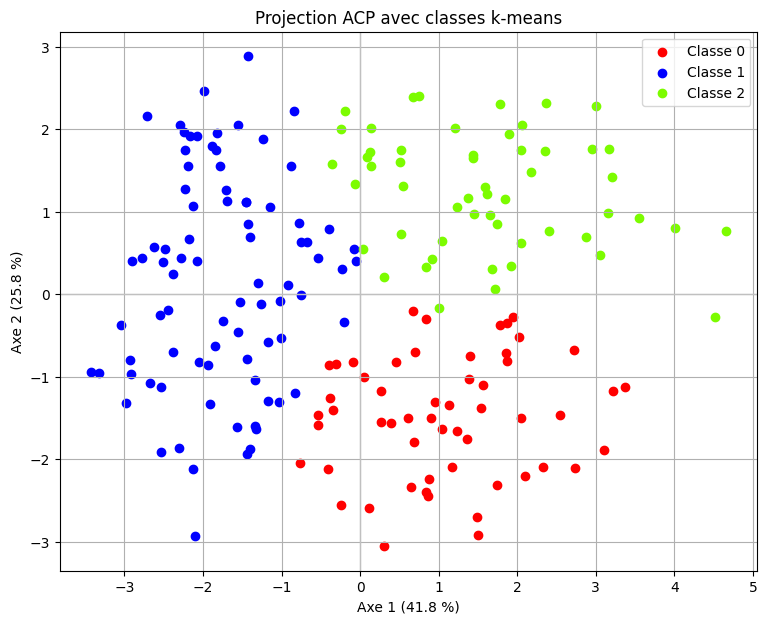

In [ ]:
# 4.5 Projection des classes sur le premier plan factoriel de l'ACP
acp = PCA()
coord = acp.fit_transform(Z)
inert_acp = acp.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 7))
for k, couleur in zip(range(K_CLASSES), ["red", "blue", "lawngreen", "aqua", "orange"]):
    plt.scatter(coord[kmeans.labels_ == k, 0], coord[kmeans.labels_ == k, 1],
                c=couleur, label=f"Classe {k}")
plt.axhline(0, color="silver", linewidth=1)
plt.axvline(0, color="silver", linewidth=1)
plt.xlabel(f"Axe 1 ({inert_acp[0]:.1f} %)")
plt.ylabel(f"Axe 2 ({inert_acp[1]:.1f} %)")
plt.title("Projection ACP avec classes k-means")
plt.legend()
plt.grid(True)
plt.show()

## 4.6 Comparaison avec la CAH (ARI) et taux de bon classement


Ici la CAH est recalculée avec Ward sur les mêmes données.

 **à remplacer `labels_cah` par les étiquettes de Neji**

In [ ]:
cah = AgglomerativeClustering(n_clusters=K_CLASSES, linkage="ward").fit(Z)
labels_cah = cah.labels_
df["classe_cah"] = labels_cah

# Tableau croisé CAH x k-means
display(pd.crosstab(df["classe_kmeans"], df["classe_cah"],
                    rownames=["k-means"], colnames=["CAH"]))

# Indice de Rand ajusté : 1 = partitions identiques, 0 = accord dû au hasard
ari = adjusted_rand_score(labels_cah, kmeans.labels_)
print("ARI (CAH vs k-means) :", round(ari, 3))

# Variable de segmentation : experience_level
print("ARI (k-means vs experience_level) :", round(adjusted_rand_score(df["experience_level"], kmeans.labels_), 3))
print("ARI (CAH     vs experience_level) :", round(adjusted_rand_score(df["experience_level"], labels_cah), 3))

CAH,0,1,2
k-means,,,
0,8,46,1
1,79,0,4
2,1,6,47


ARI (CAH vs k-means) : 0.723
ARI (k-means vs experience_level) : 0.302
ARI (CAH     vs experience_level) : 0.279


In [ ]:
# Taux de bon classement : on associe à chaque classe sa modalité majoritaire
def taux_bon_classement(classes, reference):
    tab = pd.crosstab(classes, reference)
    return tab.max(axis=1).sum() / tab.values.sum()

print("Taux de bon classement k-means vs experience_level :",
      round(taux_bon_classement(df["classe_kmeans"], df["experience_level"]), 3))
print("Taux de bon classement CAH     vs experience_level :",
      round(taux_bon_classement(df["classe_cah"], df["experience_level"]), 3))
print("Taux de bon classement k-means vs salary_class     :",
      round(taux_bon_classement(df["classe_kmeans"], df["salary_class"]), 3))
print("Taux de bon classement CAH     vs salary_class     :",
      round(taux_bon_classement(df["classe_cah"], df["salary_class"]), 3))

Taux de bon classement k-means vs experience_level : 0.5
Taux de bon classement CAH     vs experience_level : 0.51
Taux de bon classement k-means vs salary_class     : 0.641
Taux de bon classement CAH     vs salary_class     : 0.641


##Interprétation

#Régression linéaire multiple

Modèle : `employee_satisfaction ~ salary_usd + layoff_risk + work_life_balance_score`

Y = β0 + β1·salary_usd + β2·layoff_risk + β3·work_life_balance_score + ε

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

EXPL = ["salary_usd", "layoff_risk", "work_life_balance_score"]
y = df["employee_satisfaction"]
Xr = sm.add_constant(df[EXPL])

modele = sm.OLS(y, Xr).fit()
print(modele.summary())

                              OLS Regression Results                             
Dep. Variable:     employee_satisfaction   R-squared:                       0.472
Model:                               OLS   Adj. R-squared:                  0.464
Method:                    Least Squares   F-statistic:                     56.10
Date:                   Sun, 22 Nov 2026   Prob (F-statistic):           6.01e-26
Time:                           20:07:40   Log-Likelihood:                -596.32
No. Observations:                    192   AIC:                             1201.
Df Residuals:                        188   BIC:                             1214.
Df Model:                              3                                         
Covariance Type:               nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

In [ ]:
# Poids relatif des variables : coefficients standardisés (comparables entre eux)
coef_std = modele.params[EXPL] * df[EXPL].std() / y.std()
print("Coefficients standardisés :")
print(coef_std.round(3))

# Effet pratique : on exprime les coefficients pour une variation « réaliste »
print("\n+10 000 $ de salaire        ->", round(modele.params["salary_usd"] * 10000, 2), "points de satisfaction")
print("+0,10 de risque de licenciement ->", round(modele.params["layoff_risk"] * 0.10, 2), "points de satisfaction")
print("+10 points de work-life balance ->", round(modele.params["work_life_balance_score"] * 10, 2), "points de satisfaction")

Coefficients standardisés :
salary_usd                 0.293
layoff_risk               -0.313
work_life_balance_score    0.485
dtype: float64

+10 000 $ de salaire        -> 0.56 points de satisfaction
+0,10 de risque de licenciement -> -1.67 points de satisfaction
+10 points de work-life balance -> 2.68 points de satisfaction


## Vérification des hypothèses du modèle

Noor : IDK whats this , when i concentrate more i will decide wether worth keeping it or not

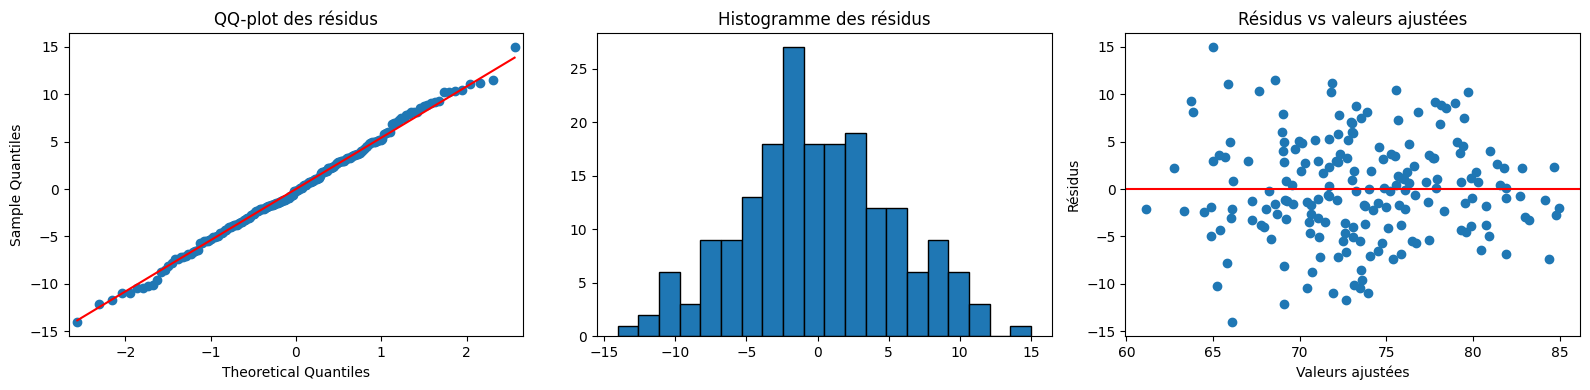

Shapiro-Wilk (normalité)      : p = 0.8661
Breusch-Pagan (variance cste) : p = 0.0018
Durbin-Watson (indépendance)  : 2.1 (proche de 2 = pas d'autocorrélation)


,variable,VIF
0,const,1.00
1,salary_usd,1.70
2,layoff_risk,1.72
3,work_life_balance_score,1.02


In [ ]:
residus = modele.resid
ajustes = modele.fittedvalues

# 1) Normalité des résidus : QQ-plot + test de Shapiro-Wilk
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sm.qqplot(residus, line="s", ax=axes[0])
axes[0].set_title("QQ-plot des résidus")
axes[1].hist(residus, bins=20, edgecolor="black")
axes[1].set_title("Histogramme des résidus")

# 2) Homoscédasticité : résidus vs valeurs ajustées
axes[2].scatter(ajustes, residus)
axes[2].axhline(0, color="red")
axes[2].set_xlabel("Valeurs ajustées")
axes[2].set_ylabel("Résidus")
axes[2].set_title("Résidus vs valeurs ajustées")
plt.tight_layout()
plt.show()

print("Shapiro-Wilk (normalité)      : p =", round(stats.shapiro(residus).pvalue, 4))
print("Breusch-Pagan (variance cste) : p =", round(het_breuschpagan(residus, Xr)[1], 4))
print("Durbin-Watson (indépendance)  :", round(durbin_watson(residus), 3), "(proche de 2 = pas d'autocorrélation)")

# 3) Colinéarité entre variables explicatives : VIF
vif = pd.DataFrame({"variable": Xr.columns,
                    "VIF": [variance_inflation_factor(Xr.values, i) for i in range(Xr.shape[1])]})
display(vif.round(2))